# Notebook 11 — `11_xgboost_shap_sectors_matched`

## Overview

**Purpose:** Matched-control version of the 17-sector predictive pipeline: the
per-sector XGBoost + SHAP run is repeated on the subsample of regencies with
near-uniform population and schooling, then compared against the fixed-effects
flood-block results from `fit_9b.json`. The manuscript reports that the two
sectors with weak positive full-sample test R² fall to zero (2/17 → 0/17) and the
top SHAP feature shifts to schooling in most sectors, confirming the sector
predictive skill was control-driven.

## Data requirements

This notebook runs on the model-ready panel exported by Notebook 8; no raw data
download is required here.

| Input | Produced by | Directory |
|---|---|---|
| Model-ready panel (`transformed` sheet) | Notebook 8 | `data/processed/8_panel_data.xlsx` |

Additionally reads `fit_9b.json` (the 3-dimension sector FE results from Notebook 9b).

## Workflow

| Step | Description |
|---|---|
| 1 | Setup and parameter grid |
| 2 | Matched-control subsample (near-uniform population and schooling) |
| 3 | Per-sector pipeline function |
| 4 | Run the pipeline across the 17 sectors (per `SECTORS_TO_RUN`) |
| 5 | FE vs XGBoost comparison (FE read from `fit_9b.json`) |

## Outputs

| File | Description |
|---|---|
| (in-notebook) | Per-sector matched-subsample CV-R² and flood SHAP-share, with the FE comparison table |

---
## STEP 1 — Setup and parameter grid

Import libraries and define the full parameter grid (identical to the headline growth run) used by the per-sector pipeline below.

In [1]:
# ═════════════════════════════════════════════════════════════
# STEP 1 — Setup & parameter grid
# ═════════════════════════════════════════════════════════════
import pandas as pd, numpy as np, warnings, json
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import xgboost as xgb, shap
from sklearn.model_selection import GroupKFold, GridSearchCV, cross_val_score, learning_curve
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.base import clone

panel = pd.read_excel("../data/processed/8_panel_data.xlsx", "transformed").sort_values(["bps_kab_code", "year"])
FLOOD    = ["event_count_log", "HCI_log", "PDI_log"]
CONTROLS = ["log_population", "rls_years"]
FEATURES = FLOOD + CONTROLS
SECTORS  = [c for c in panel.columns
            if c.startswith("grdp_") and c.endswith("growth") and c != "grdp_growth_pct"]

# ── SWITCH: test one sector first, then set to SECTORS for all 17 ──
# SECTORS_TO_RUN = ["grdp_G_trade_growth"]     # ← change to SECTORS for the full run
SECTORS_TO_RUN = SECTORS

print(f"Will run: {[s.replace('grdp_','').replace('_growth','') for s in SECTORS_TO_RUN]}")

Will run: ['A_agriculture', 'B_mining', 'C_manufacturing', 'D_electricity', 'E_water', 'F_construction', 'G_trade', 'H_transport', 'I_accommodation', 'J_infocomm', 'K_finance', 'L_realestate', 'MN_business', 'O_government', 'P_education', 'Q_health', 'RSTU_other']


## STEP 2 — Matched-control subsample

Filter applied **per regency** (2016–2025 mean of each control), keeping all 10 years of every
surviving regency, so the panel stays balanced. The two controls are screened **separately** —
they are on different scales, so combining them into one score would be meaningless.

In [4]:
# ═════════════════════════════════════════════════════════════
# STEP 2 — Matched-control subsample
# ═════════════════════════════════════════════════════════════
# ═══════════════════════════════════════════════════════════════════
# MATCHED-CONTROL SUBSAMPLE  (supervisor request)
# ═══════════════════════════════════════════════════════════════════
# Rationale: the full-sample models show that where predictive power
# exists (poverty, unemployment) it comes from the CONTROL variables,
# not from flooding. To test whether the weak flood signal is merely an
# artefact of variation in those controls, we restrict the sample to
# regencies that are SIMILAR to one another in population and education.
# If flooding still carries no signal once the controls are (near-)
# uniform, the null result is that much more credible.
#
# Design choice — filter at the REGENCY level, not regency-year:
#   1. Collapse each regency to its 2016-2025 MEAN of log_population and
#      rls_years  → one profile per regency.
#   2. Keep regencies whose BOTH means fall inside a narrow band around
#      the median (median ± K_SD × SD). The two controls are screened
#      SEPARATELY — they are on different scales/units, so summing or
#      averaging them together would be meaningless.
#   3. Retain ALL 10 years for every regency that survives.
# This keeps the panel balanced. Filtering on regency-YEAR instead would
# drop individual years within a regency, which would selectively remove
# within-regency variation and bias the estimates.

K_SD = 0.5   # band half-width in SDs; 0.5 → ~111 regencies (~22% of 514)

_prof = (panel.groupby("bps_kab_code")
              .agg(avg_pop=("log_population","mean"),
                   avg_rls=("rls_years","mean"))
              .reset_index())

_lo_p, _hi_p = _prof.avg_pop.median() - K_SD*_prof.avg_pop.std(), _prof.avg_pop.median() + K_SD*_prof.avg_pop.std()
_lo_r, _hi_r = _prof.avg_rls.median() - K_SD*_prof.avg_rls.std(), _prof.avg_rls.median() + K_SD*_prof.avg_rls.std()

_keep = _prof[_prof.avg_pop.between(_lo_p,_hi_p) & _prof.avg_rls.between(_lo_r,_hi_r)]["bps_kab_code"]

panel_full = panel.copy()                       # keep a handle on the full panel
panel      = panel[panel.bps_kab_code.isin(_keep)].copy()   # <-- everything below now runs on the subsample

print("MATCHED-CONTROL SUBSAMPLE")
print(f"  band: median ± {K_SD}·SD, applied to log_population AND rls_years separately")
print(f"    log_population in [{_lo_p:.2f}, {_hi_p:.2f}]")
print(f"    rls_years      in [{_lo_r:.2f}, {_hi_r:.2f}]")
print(f"  regencies kept : {panel.bps_kab_code.nunique()} of {panel_full.bps_kab_code.nunique()}"
      f"  ({100*panel.bps_kab_code.nunique()/panel_full.bps_kab_code.nunique():.1f}%)")
print(f"  rows           : {len(panel)} of {len(panel_full)}   (panel stays balanced: "
      f"{len(panel)//max(panel.bps_kab_code.nunique(),1)} years per regency)")

# How much control variation did we actually remove? (this is the point)
print("\\n  SD of the controls, full sample → subsample:")
for _c in ["log_population","rls_years"]:
    print(f"    {_c:<16} {panel_full[_c].std():.3f} → {panel[_c].std():.3f}"
          f"   ({100*(1-panel[_c].std()/panel_full[_c].std()):.0f}% reduction)")

print("\\n  NOTE: with the controls made near-uniform, any predictive power they")
print("  previously supplied is largely removed. Expect R² to FALL — especially")
print("  for poverty, whose full-sample R² was ~87% control-driven. A drop is not")
print("  a failure: it CONFIRMS the earlier SHAP finding by design.")


MATCHED-CONTROL SUBSAMPLE
  band: median ± 0.5·SD, applied to log_population AND rls_years separately
    log_population in [12.05, 13.07]
    rls_years      in [7.44, 9.07]
  regencies kept : 111 of 514  (21.6%)
  rows           : 1110 of 5140   (panel stays balanced: 10 years per regency)
\n  SD of the controls, full sample → subsample:
    log_population   1.023 → 0.286   (72% reduction)
    rls_years        1.665 → 0.544   (67% reduction)
\n  NOTE: with the controls made near-uniform, any predictive power they
  previously supplied is largely removed. Expect R² to FALL — especially
  for poverty, whose full-sample R² was ~87% control-driven. A drop is not
  a failure: it CONFIRMS the earlier SHAP finding by design.


In [5]:
# Full nb11 parameter grid (324 combinations) — identical to headline growth
PARAM_GRID = {
    "n_estimators":     [100, 300, 500],
    "max_depth":        [2, 3, 4],
    "learning_rate":    [0.01, 0.05, 0.1],
    "subsample":        [0.8],
    "colsample_bytree": [0.8],
    "min_child_weight": [5, 10],
    "reg_alpha":        [0, 0.1, 1.0],
    "reg_lambda":       [1.0, 5.0],
}

def cv_metrics(est, X, y, groups, cv):
    r2s, rmses, maes = [], [], []
    for tr_i, te_i in cv.split(X, y, groups):
        m = clone(est); m.fit(X[tr_i], y[tr_i]); p = m.predict(X[te_i])
        r2s.append(r2_score(y[te_i], p)); rmses.append(np.sqrt(mean_squared_error(y[te_i], p)))
        maes.append(mean_absolute_error(y[te_i], p))
    return np.mean(r2s), np.std(r2s), np.mean(rmses), np.mean(maes)

print("Grid ready:", int(np.prod([len(v) for v in PARAM_GRID.values()])), "combinations")

Grid ready: 324 combinations


In [6]:
def run_full_sector(outcome):
    """Full nb11 pipeline for one outcome. Prints tables, draws all plots,
    returns a summary dict for the final FE-vs-XGBoost comparison."""
    name = outcome.replace("grdp_", "").replace("_growth", "")
    print("\n" + "#"*70)
    print(f"#  SECTOR: {name}")
    print("#"*70)

    d = panel.dropna(subset=[outcome] + FEATURES).copy()
    tr = d[d.year <= 2022]; va = d[d.year == 2023]; te = d[d.year >= 2024]
    X_tr, y_tr, g_tr = tr[FEATURES].values, tr[outcome].values, tr["bps_kab_code"].values
    X_va, y_va = va[FEATURES].values, va[outcome].values
    X_te, y_te = te[FEATURES].values, te[outcome].values
    gkf = GroupKFold(5)

    # ---- 1. TUNING ----
    gs = GridSearchCV(xgb.XGBRegressor(random_state=42, objective="reg:squarederror"),
                      PARAM_GRID, cv=gkf.split(X_tr, y_tr, g_tr),
                      scoring="r2", n_jobs=-1)
    gs.fit(X_tr, y_tr); best = gs.best_estimator_
    print(f"\nBest params: {gs.best_params_}")
    print(f"Best grouped-CV R2 (train): {gs.best_score_:+.4f}")

    # ---- 2. THREE-STAGE EVAL ----
    cv_r2, cv_sd, cv_rmse, cv_mae = cv_metrics(best, X_tr, y_tr, g_tr, gkf)
    def stg(yt, yp): return r2_score(yt, yp), np.sqrt(mean_squared_error(yt, yp)), mean_absolute_error(yt, yp)
    r2_va, rmse_va, mae_va = stg(y_va, best.predict(X_va))
    r2_te, rmse_te, mae_te = stg(y_te, best.predict(X_te))
    naive = np.full(len(y_te), y_tr.mean()); r2_n, rmse_n, mae_n = stg(y_te, naive)
    print("\nPERFORMANCE ACROSS THE THREE STAGES")
    print(f"  {'Stage':<22}{'R2':>9}{'RMSE':>9}{'MAE':>9}")
    print(f"  {'Train (CV)':<22}{cv_r2:>+9.4f}{cv_rmse:>9.3f}{cv_mae:>9.3f}")
    print(f"  {'Validation (2023)':<22}{r2_va:>+9.4f}{rmse_va:>9.3f}{mae_va:>9.3f}")
    print(f"  {'Test (2024-25)':<22}{r2_te:>+9.4f}{rmse_te:>9.3f}{mae_te:>9.3f}")
    print(f"  {'Naive baseline':<22}{r2_n:>+9.4f}{rmse_n:>9.3f}{mae_n:>9.3f}")

    # ---- 3. VALIDATION CURVE (L1/L2) ----
    _base = dict(best.get_params()); [_base.pop(k, None) for k in ("reg_alpha","reg_lambda")]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    for ax, param, grid, fixed in [(axes[0],"reg_alpha",[0,0.1,0.5,1,2,5],{"reg_lambda":1.0}),
                                    (axes[1],"reg_lambda",[0,0.5,1,2,5,10],{"reg_alpha":0.1})]:
        vals=[]
        for gv in grid:
            kw=dict(_base); kw.update(fixed); kw[param]=gv
            m=xgb.XGBRegressor(**kw)
            vals.append(cross_val_score(m,X_tr,y_tr,cv=gkf.split(X_tr,y_tr,g_tr),scoring="r2").mean())
        ax.plot(range(len(grid)), vals, "o-", color="#1C7293")
        ax.axhline(0, color="#999", ls="--", lw=1)
        ax.set_xticks(range(len(grid))); ax.set_xticklabels(grid)
        ax.set_title(f"{name} — {param}"); ax.set_xlabel(param); ax.set_ylabel("CV-R2")
    plt.tight_layout(); plt.show()

    # ---- 4. LEARNING CURVE ----
    _d = d.dropna(subset=[outcome]+FEATURES)
    _X,_y,_g = _d[FEATURES].values,_d[outcome].values,_d["bps_kab_code"].values
    sizes, trs, cvs = learning_curve(clone(best), _X, _y, groups=_g,
                                     cv=gkf, train_sizes=np.linspace(0.2,1.0,5), scoring="r2")
    plt.figure(figsize=(7,3.4))
    plt.plot(sizes, trs.mean(1), "o-", color="#c0392b", label="train R2")
    plt.plot(sizes, cvs.mean(1), "s-", color="#1f6f54", label="CV R2")
    plt.axhline(0,color="#999",ls="--",lw=1); plt.legend()
    plt.title(f"{name} — learning curve"); plt.xlabel("n_train"); plt.ylabel("R2"); plt.show()

    # ---- 5. DEPTH SWEEP (under/over-fit) ----
    depths=[1,2,3,4,6,10]; d_tr=[]; d_cv=[]
    for dp in depths:
        kw=dict(_base); kw["max_depth"]=dp
        m=xgb.XGBRegressor(**kw); m.fit(X_tr,y_tr)
        d_tr.append(r2_score(y_tr,m.predict(X_tr)))
        d_cv.append(cross_val_score(m,X_tr,y_tr,cv=gkf.split(X_tr,y_tr,g_tr),scoring="r2").mean())
    plt.figure(figsize=(7,3.4))
    xp=range(len(depths))
    plt.plot(xp,d_tr,"o-",color="#c0392b",label="train R2")
    plt.plot(xp,d_cv,"s-",color="#1f6f54",label="CV R2")
    plt.fill_between(xp,d_cv,d_tr,alpha=0.1,color="#888",label="gap=overfit")
    plt.axhline(0,color="#999",ls="--",lw=1); plt.xticks(list(xp),depths); plt.legend()
    plt.title(f"{name} — under/over-fitting"); plt.xlabel("max_depth"); plt.ylabel("R2"); plt.show()

    # ---- 6. BOOTSTRAP ----
    _Xr,_yr = pd.DataFrame(_X,columns=FEATURES).reset_index(drop=True), pd.Series(_y)
    np.random.seed(42); n=len(_Xr); r2s=[]; imps=[]
    for _b in range(200):
        idx=np.random.choice(n,n,replace=True); oob=np.setdiff1d(np.arange(n),idx)
        if len(oob)<50: continue
        m=xgb.XGBRegressor(**dict(best.get_params())); m.fit(_Xr.iloc[idx],_yr.iloc[idx])
        r2s.append(r2_score(_yr.iloc[oob],m.predict(_Xr.iloc[oob])))
        imps.append(np.abs(shap.TreeExplainer(m).shap_values(_Xr.iloc[oob][:100])).mean(0))
    r2s=np.array(r2s); imps=np.array(imps)
    ci=(np.percentile(r2s,2.5),np.percentile(r2s,97.5))
    fig,(b1,b2)=plt.subplots(1,2,figsize=(11,3.2))
    b1.hist(r2s,bins=30,color="#1f6f54",alpha=0.75); b1.axvline(0,color="#c0392b",ls="--")
    b1.set_title(f"{name} — bootstrap R2  95%CI=[{ci[0]:+.3f},{ci[1]:+.3f}]"); b1.set_xlabel("OOB R2")
    means=imps.mean(0); order=np.argsort(means)
    b2.barh([FEATURES[i] for i in order],means[order],
            xerr=[(means-np.percentile(imps,2.5,0))[order],(np.percentile(imps,97.5,0)-means)[order]],
            color="#854f0b",alpha=0.75)
    b2.set_title("SHAP importance (95% CI)"); b2.set_xlabel("mean |SHAP|")
    plt.tight_layout(); plt.show()

    # ---- 7. SHAP: base value + waterfall + beeswarm + bar ----
    expl=shap.TreeExplainer(best); sv=expl.shap_values(X_te); base=expl.expected_value
    imp=np.abs(sv).mean(0); flood_share=imp[:3].sum()/imp.sum()*100
    print(f"\nSHAP base value = {base:.3f} (≈ mean {y_tr.mean():.3f})")
    print(f"flood share = {flood_share:.0f}%  |  top = {FEATURES[int(np.argmax(imp))]}")
    eo=shap.Explanation(values=sv[0],base_values=base,data=X_te[0],feature_names=FEATURES)
    shap.plots.waterfall(eo, show=True)
    shap.summary_plot(sv, pd.DataFrame(X_te,columns=FEATURES), show=True)
    shap.summary_plot(sv, pd.DataFrame(X_te,columns=FEATURES), plot_type="bar", show=True)

    # ---- 8. PRED VS ACTUAL ----
    pred=best.predict(X_te)
    plt.figure(figsize=(5,4.2))
    plt.scatter(y_te,pred,s=10,alpha=0.4,color="#1C7293")
    lims=[min(y_te.min(),pred.min()),max(y_te.max(),pred.max())]
    plt.plot(lims,lims,"--",color="#999"); plt.xlabel("actual"); plt.ylabel("predicted")
    plt.title(f"{name} — pred vs actual (corr={np.corrcoef(y_te,pred)[0,1]:.2f})"); plt.show()
    print(f"std actual={y_te.std():.2f}  std pred={pred.std():.2f} ({pred.std()/y_te.std()*100:.0f}%)")

    return dict(sector=name, best_cv_r2=gs.best_score_, cv_r2=cv_r2,
                test_r2=r2_te, flood_share=flood_share,
                top_feature=FEATURES[int(np.argmax(imp))],
                boot_ci_low=ci[0], boot_ci_high=ci[1])

print("run_full_sector() ready.")

run_full_sector() ready.


## STEP 3 — Run the pipeline (per `SECTORS_TO_RUN`)


######################################################################
#  SECTOR: A_agriculture
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 100, 'reg_alpha': 1.0, 'reg_lambda': 5.0, 'subsample': 0.8}
Best grouped-CV R2 (train): -0.0137

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              -0.0132    2.369    1.886
  Validation (2023)       -0.0482    2.357    1.781
  Test (2024-25)          -0.1719    2.582    1.995
  Naive baseline          -0.1190    2.523    1.943


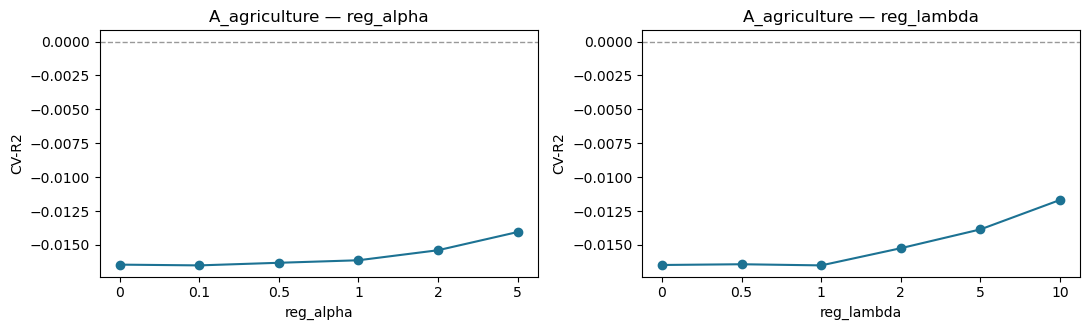

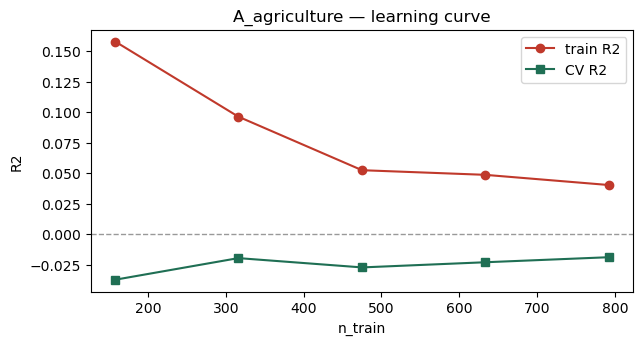

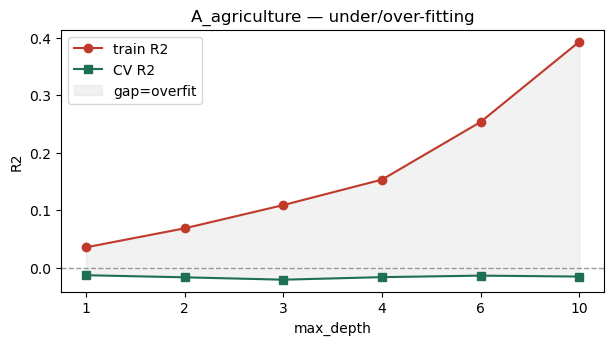

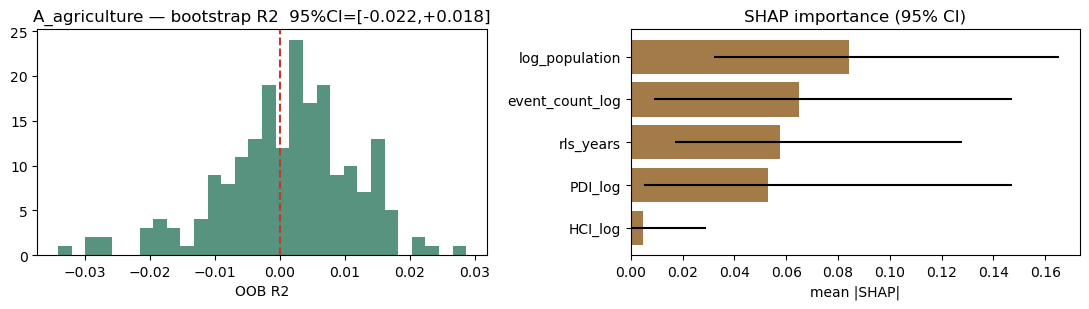


SHAP base value = 3.013 (≈ mean 3.010)
flood share = 68%  |  top = event_count_log


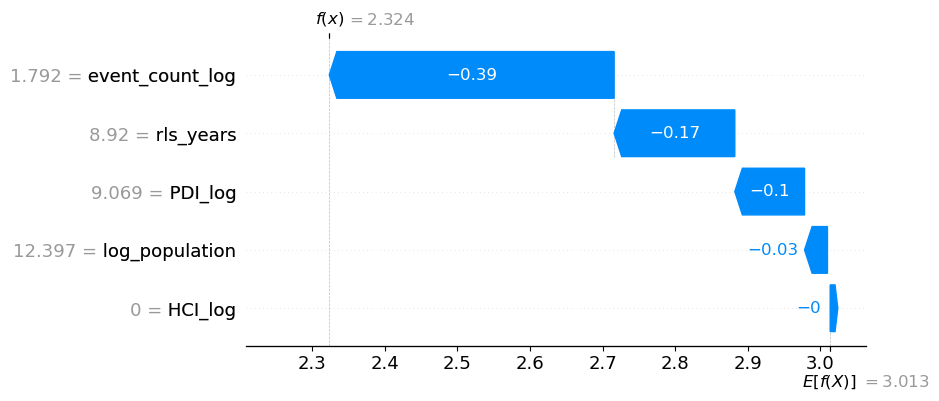

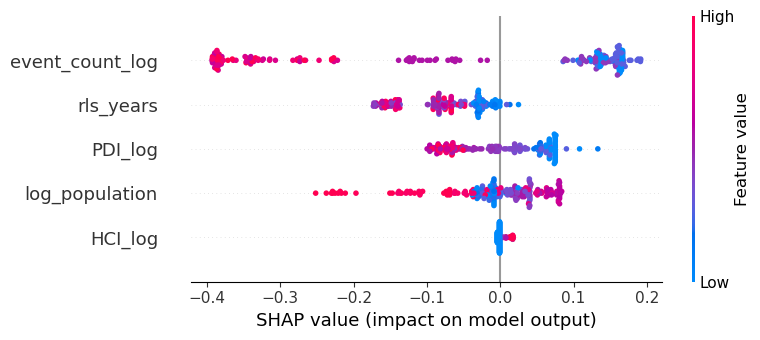

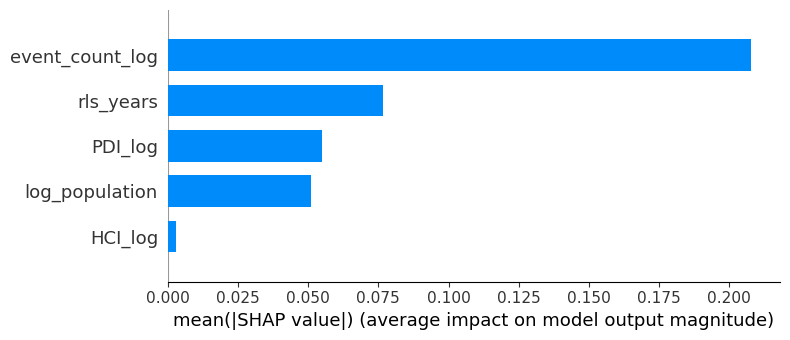

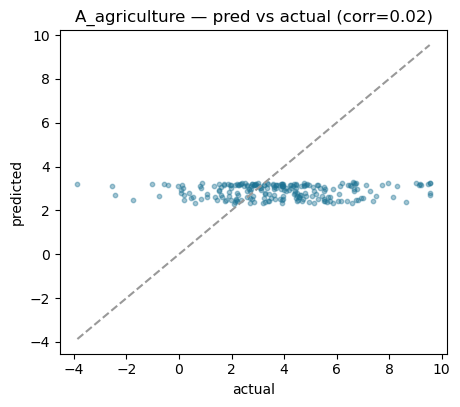

std actual=2.38  std pred=0.30 (13%)

######################################################################
#  SECTOR: B_mining
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 3, 'min_child_weight': 10, 'n_estimators': 100, 'reg_alpha': 0, 'reg_lambda': 1.0, 'subsample': 0.8}
Best grouped-CV R2 (train): +0.0140

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              +0.0145    6.311    4.420
  Validation (2023)       -0.0185    5.673    3.626
  Test (2024-25)          -0.0159    5.379    3.740
  Naive baseline          -0.0184    5.386    3.718


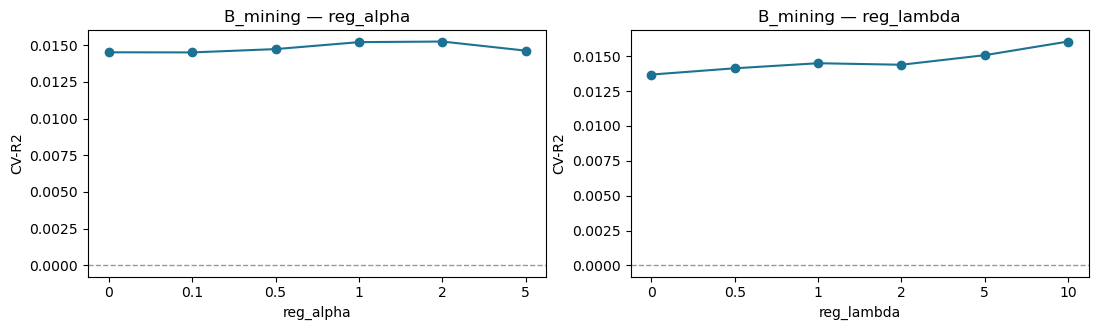

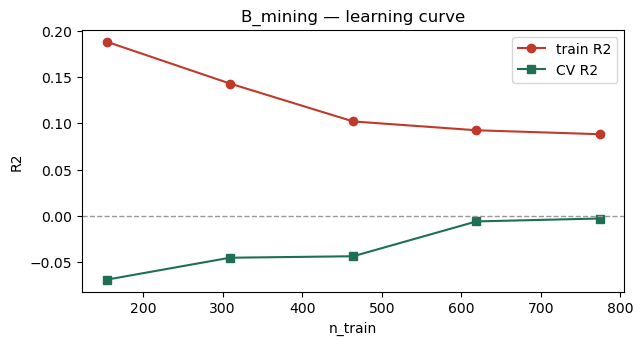

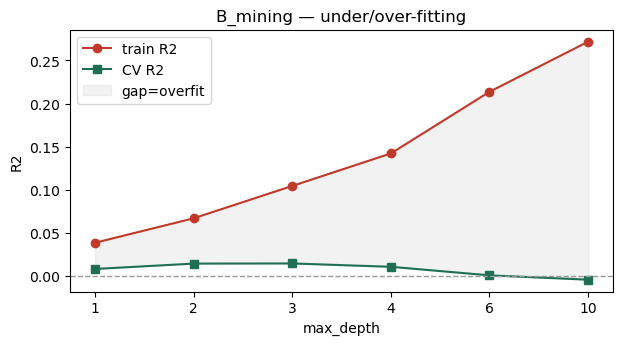

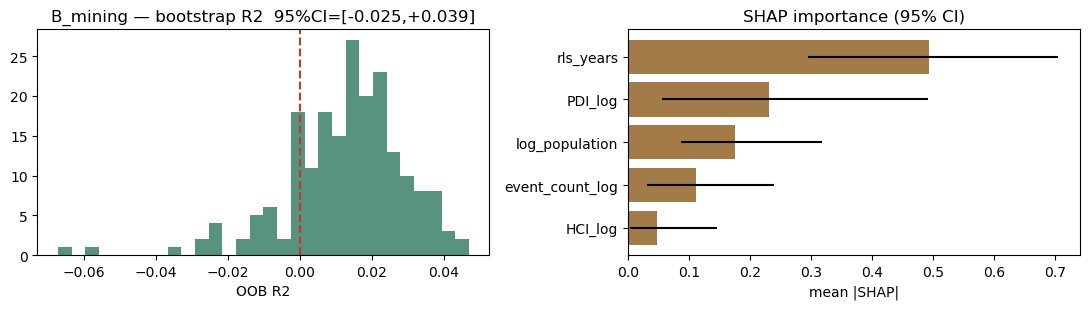


SHAP base value = 3.823 (≈ mean 3.836)
flood share = 34%  |  top = rls_years


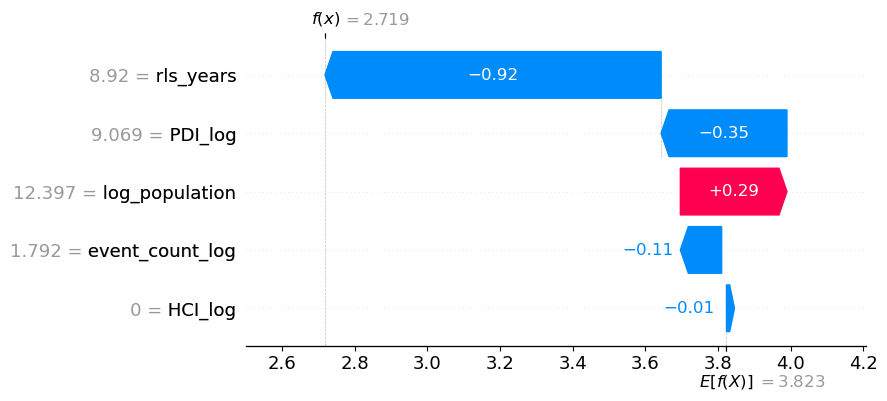

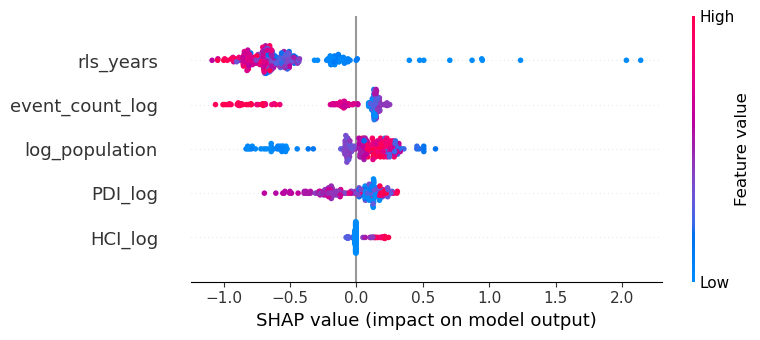

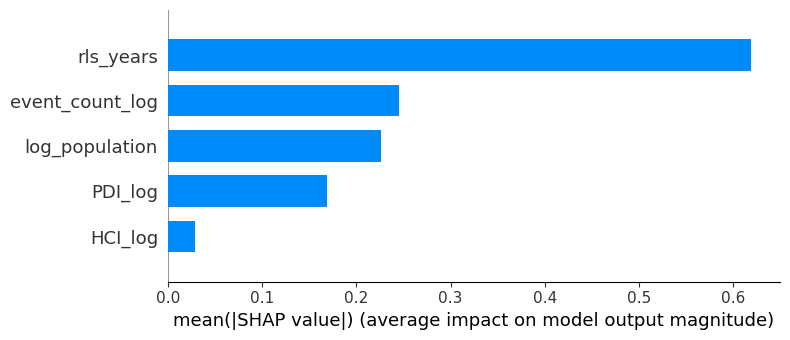

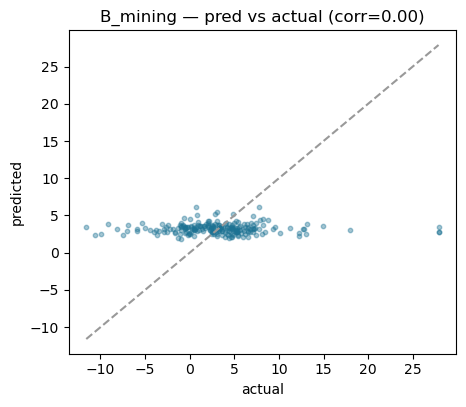

std actual=5.34  std pred=0.68 (13%)

######################################################################
#  SECTOR: C_manufacturing
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 10, 'n_estimators': 100, 'reg_alpha': 1.0, 'reg_lambda': 5.0, 'subsample': 0.8}
Best grouped-CV R2 (train): +0.0033

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              +0.0029    4.750    3.307
  Validation (2023)       +0.0033    4.533    2.844
  Test (2024-25)          -0.2319    5.777    3.662
  Naive baseline          -0.1918    5.682    3.603


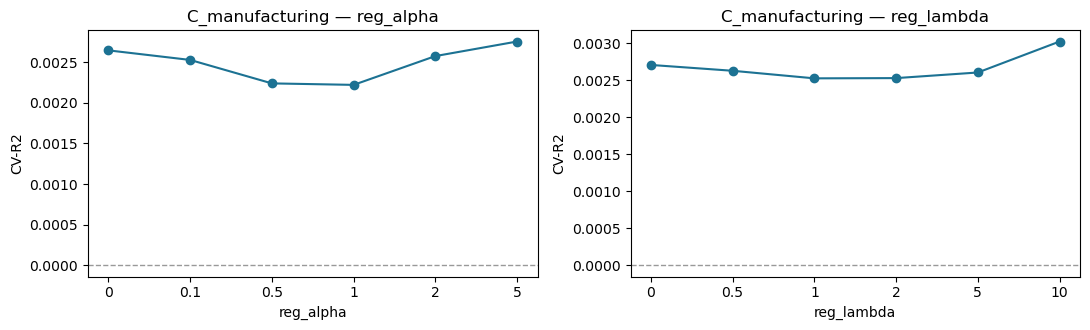

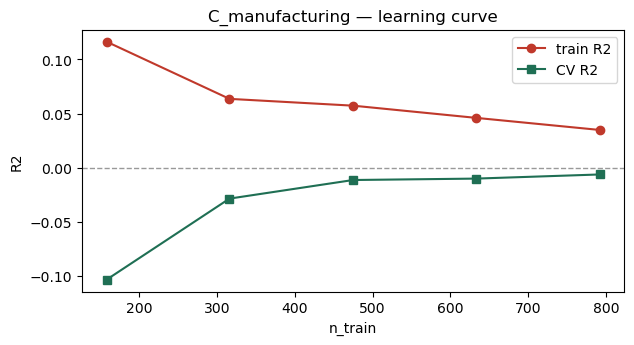

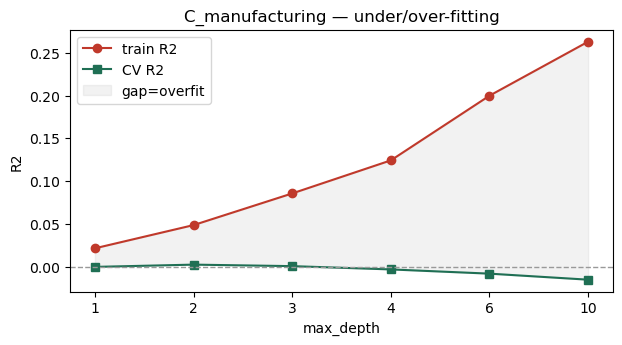

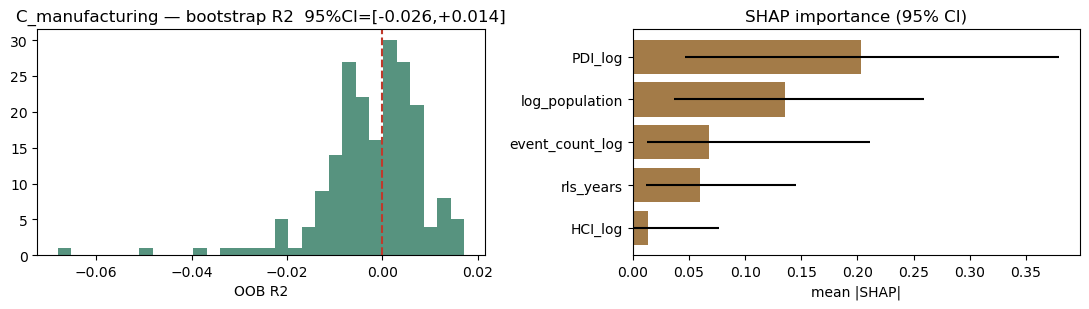


SHAP base value = 3.680 (≈ mean 3.675)
flood share = 51%  |  top = rls_years


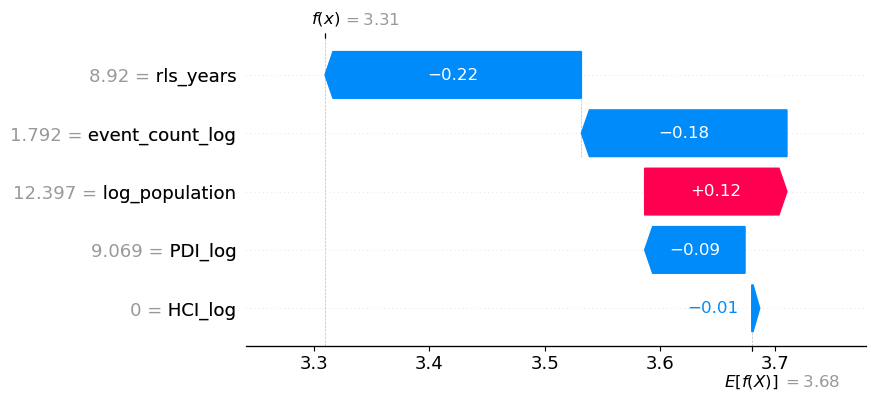

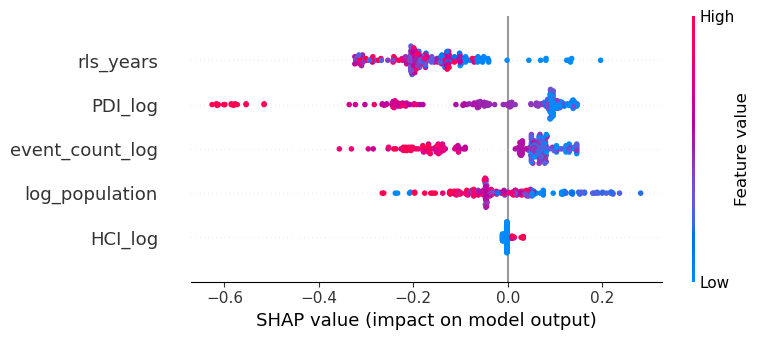

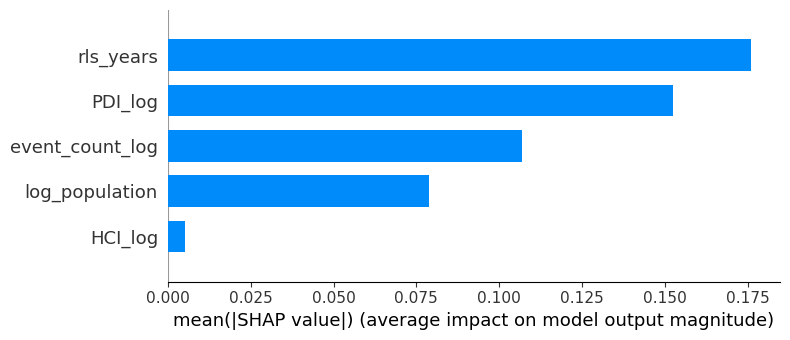

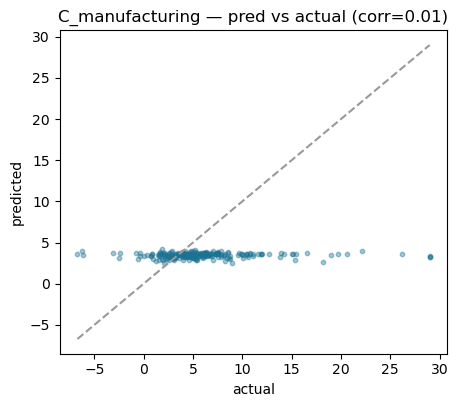

std actual=5.20  std pred=0.29 (6%)

######################################################################
#  SECTOR: D_electricity
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 100, 'reg_alpha': 0.1, 'reg_lambda': 1.0, 'subsample': 0.8}
Best grouped-CV R2 (train): -0.0053

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              -0.0068    4.484    3.089
  Validation (2023)       -0.1884    4.473    3.386
  Test (2024-25)          -0.0060    5.273    3.503
  Naive baseline          -0.0039    5.267    3.549


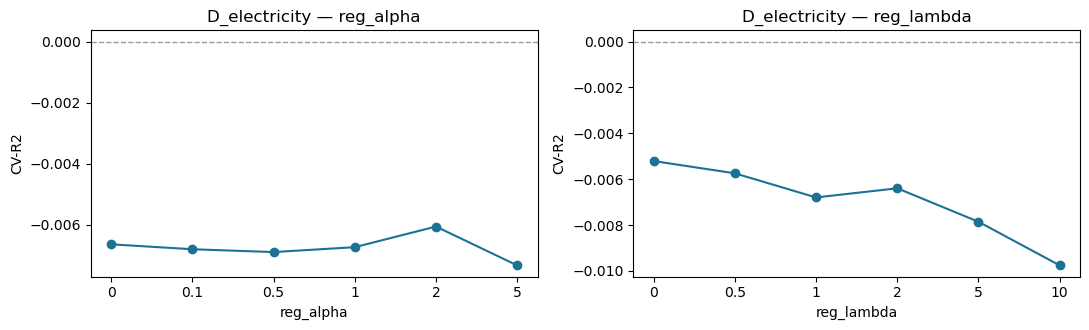

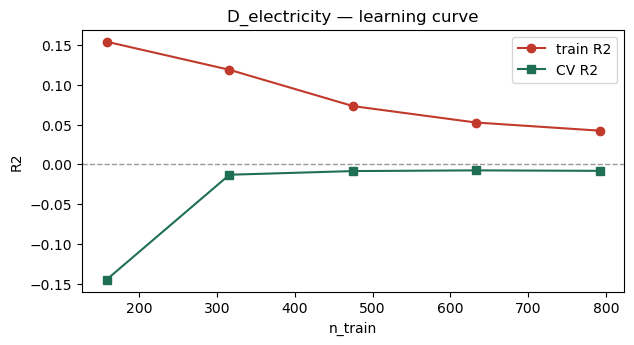

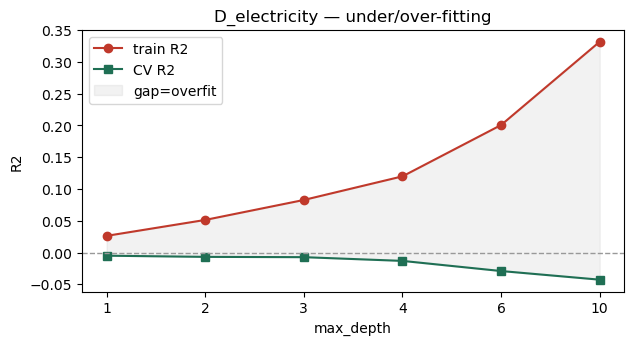

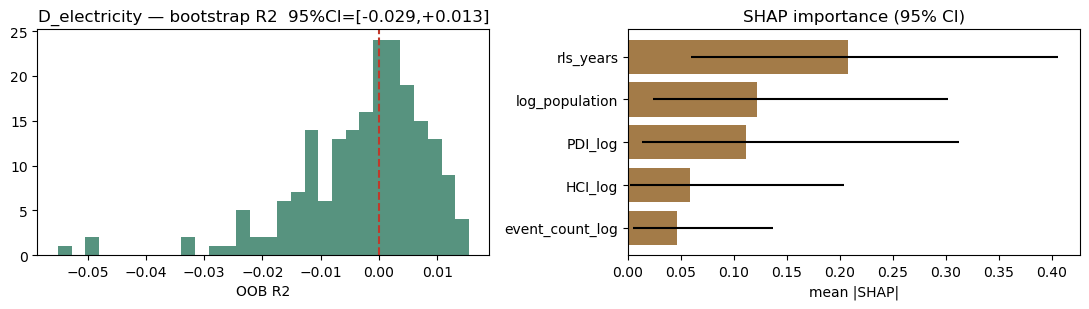


SHAP base value = 5.699 (≈ mean 5.700)
flood share = 51%  |  top = rls_years


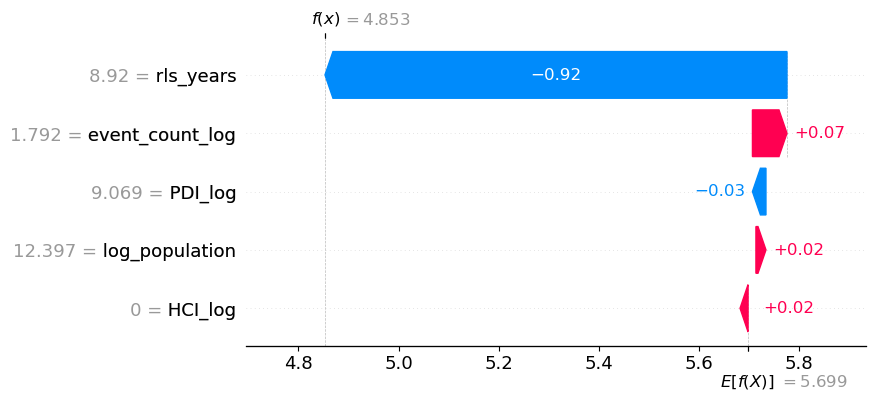

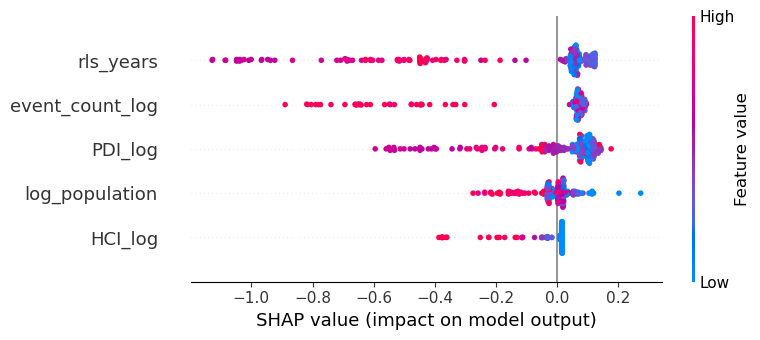

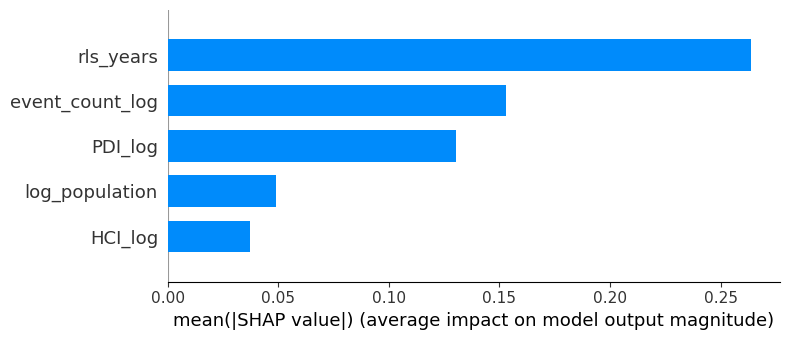

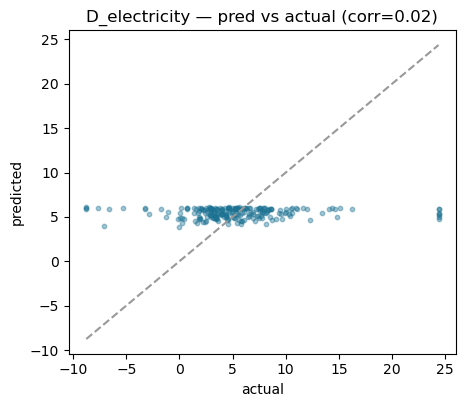

std actual=5.26  std pred=0.53 (10%)

######################################################################
#  SECTOR: E_water
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 100, 'reg_alpha': 1.0, 'reg_lambda': 5.0, 'subsample': 0.8}
Best grouped-CV R2 (train): -0.0111

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              -0.0111    3.277    2.539
  Validation (2023)       -0.0338    2.964    2.256
  Test (2024-25)          -0.1005    3.412    2.640
  Naive baseline          -0.1675    3.514    2.734


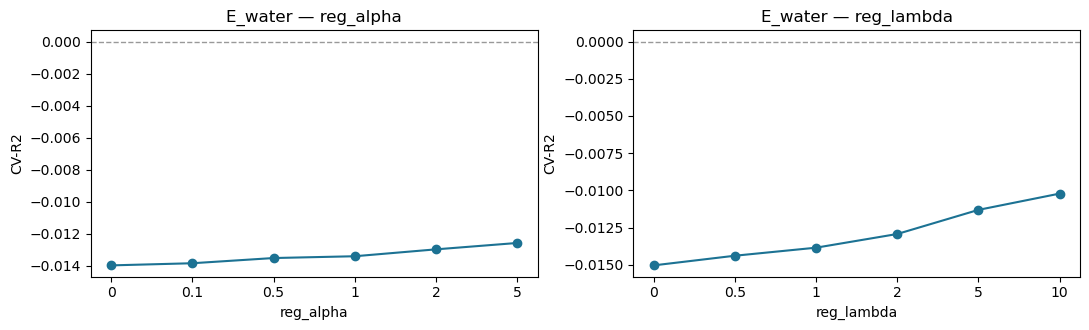

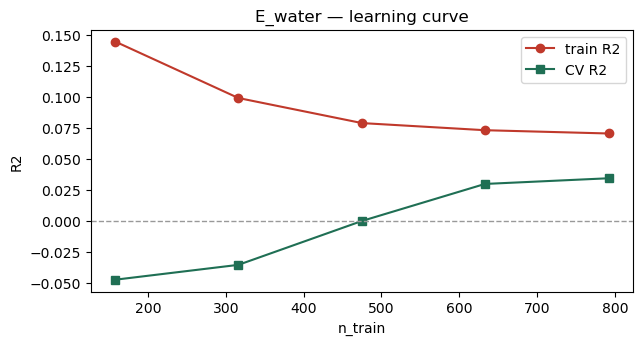

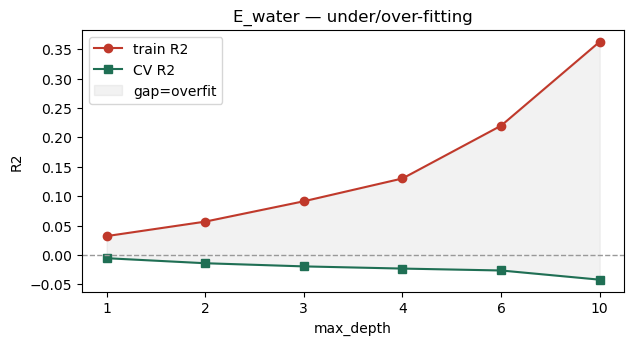

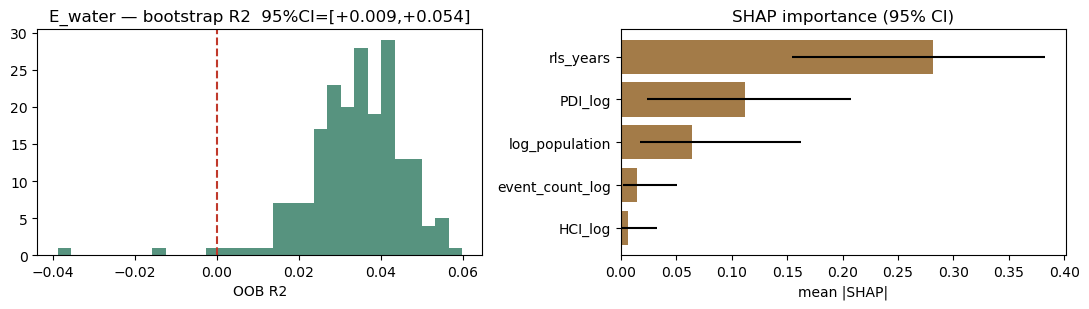


SHAP base value = 4.402 (≈ mean 4.396)
flood share = 23%  |  top = rls_years


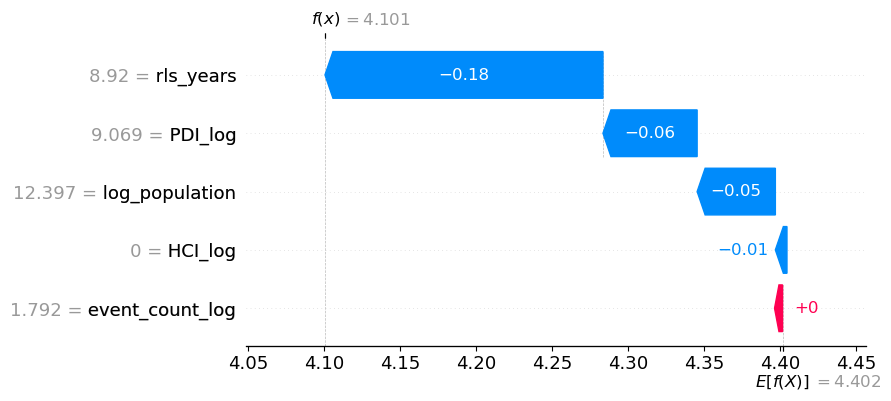

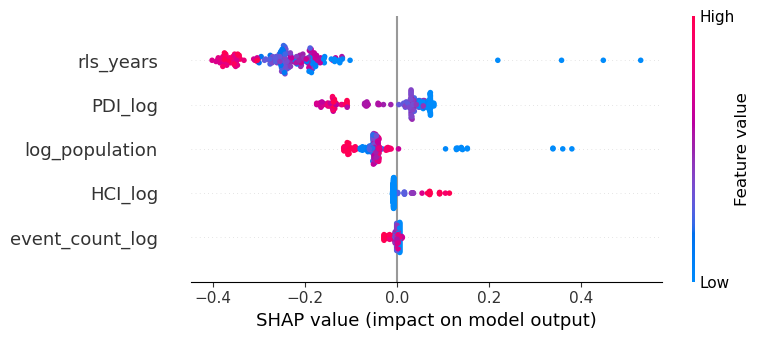

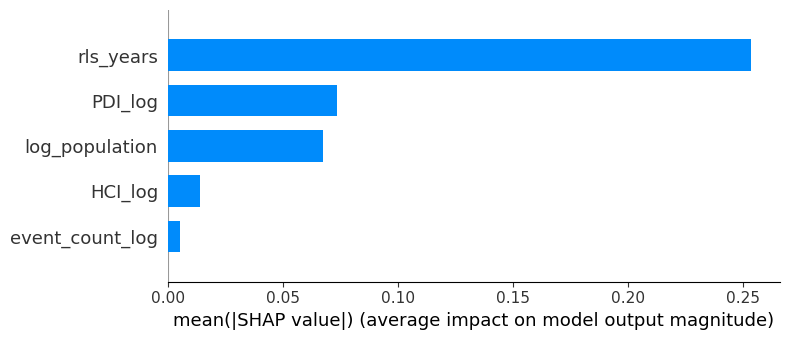

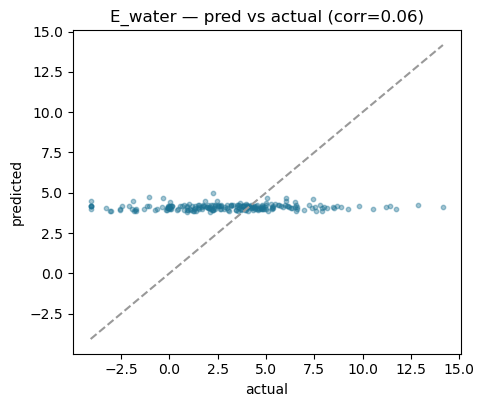

std actual=3.25  std pred=0.17 (5%)

######################################################################
#  SECTOR: F_construction
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 100, 'reg_alpha': 0, 'reg_lambda': 5.0, 'subsample': 0.8}
Best grouped-CV R2 (train): +0.0083

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              +0.0077    4.926    3.627
  Validation (2023)       -0.1485    4.796    3.329
  Test (2024-25)          -0.0372    4.759    3.488
  Naive baseline          -0.0578    4.806    3.482


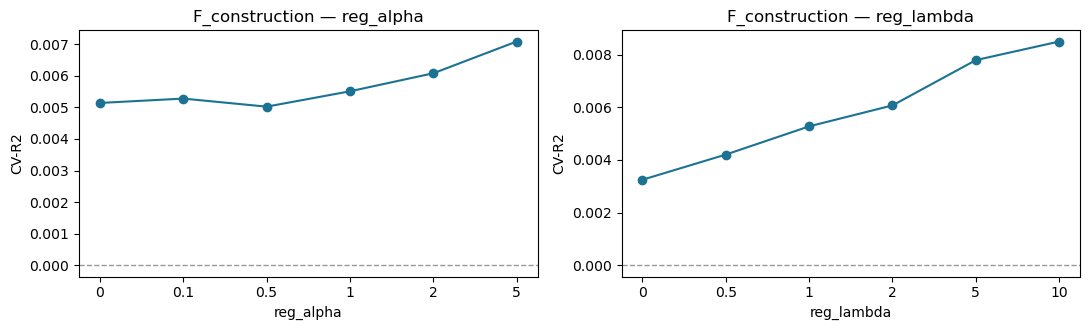

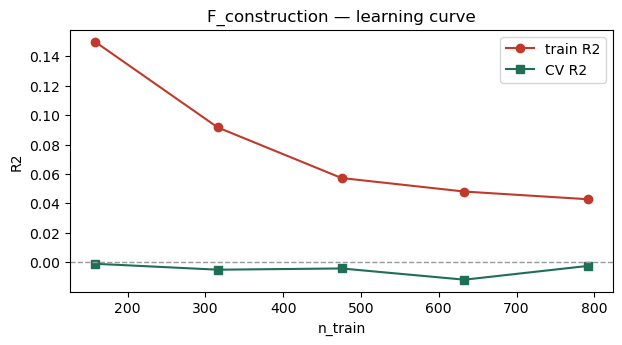

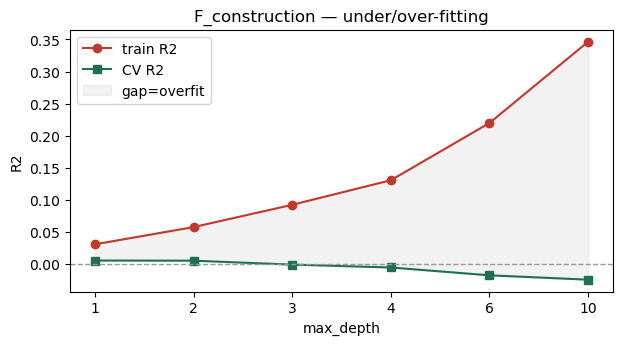

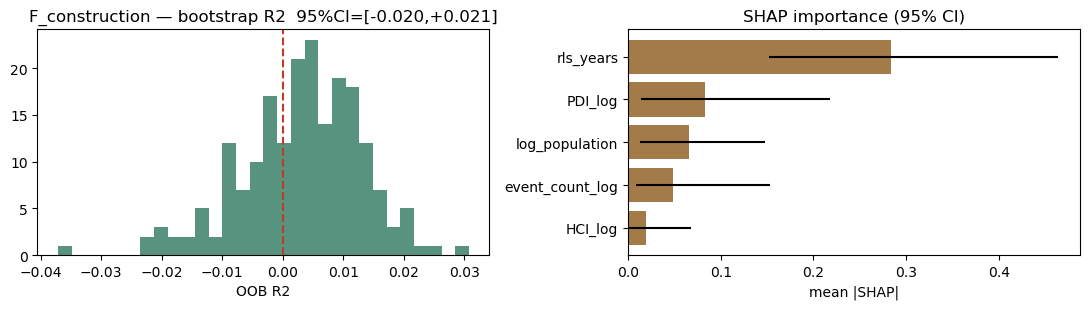


SHAP base value = 4.446 (≈ mean 4.436)
flood share = 42%  |  top = rls_years


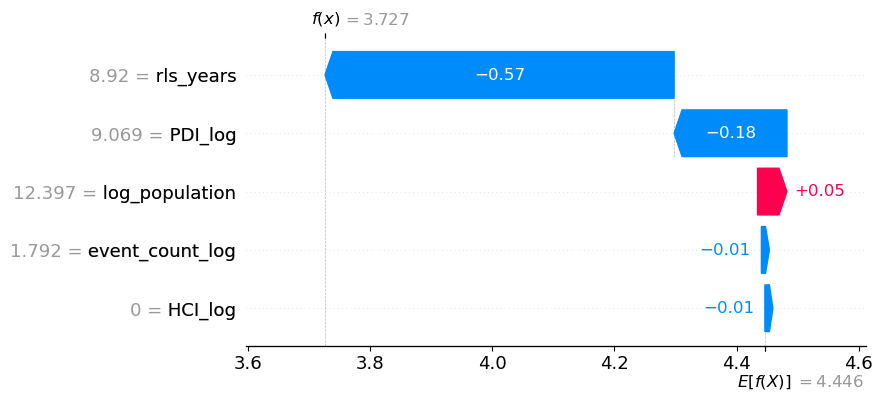

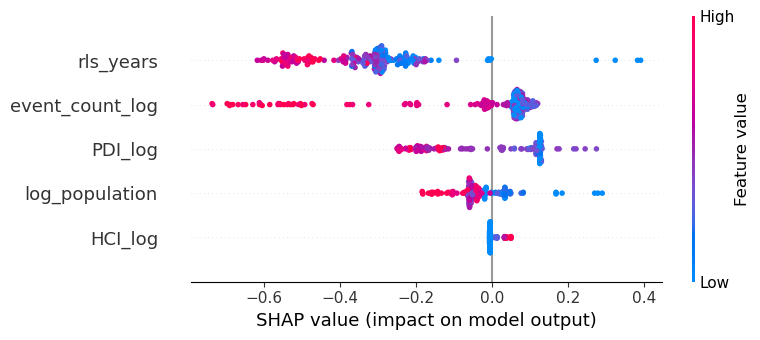

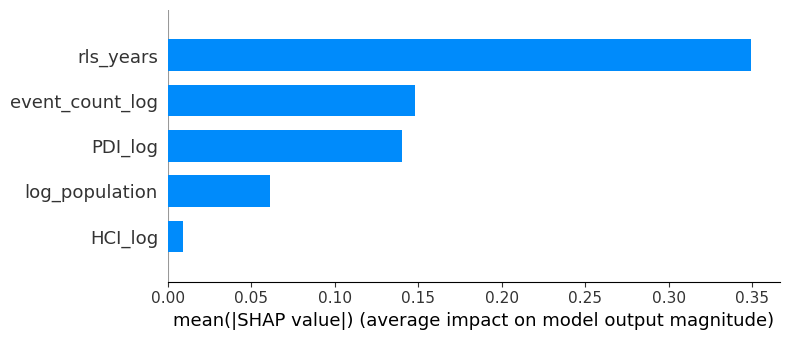

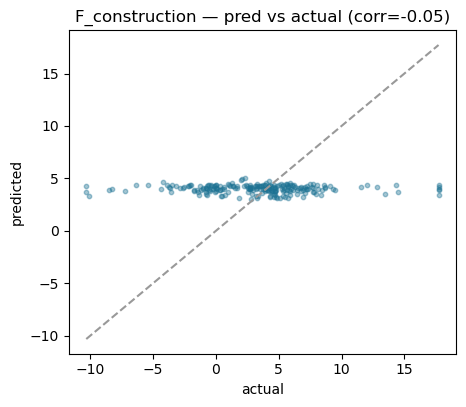

std actual=4.67  std pred=0.37 (8%)

######################################################################
#  SECTOR: G_trade
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 10, 'n_estimators': 100, 'reg_alpha': 0, 'reg_lambda': 1.0, 'subsample': 0.8}
Best grouped-CV R2 (train): +0.0040

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              +0.0038    4.345    3.227
  Validation (2023)       -0.5414    3.071    2.386
  Test (2024-25)          -0.3847    2.904    2.125
  Naive baseline          -0.2201    2.726    1.936


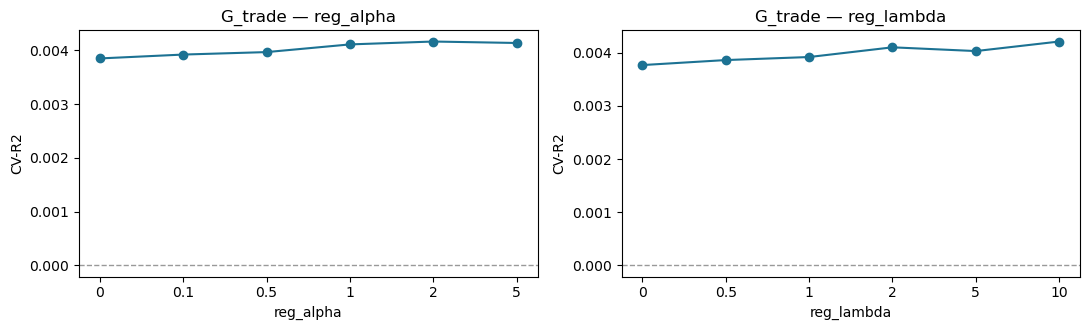

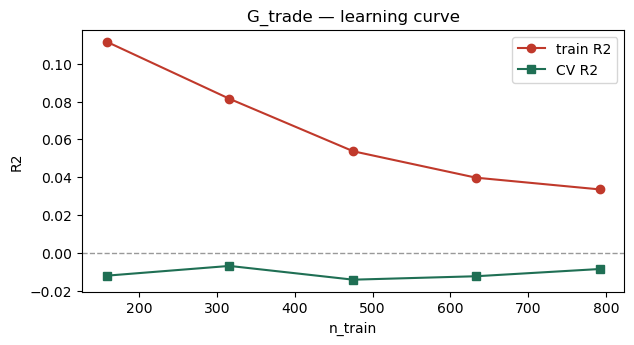

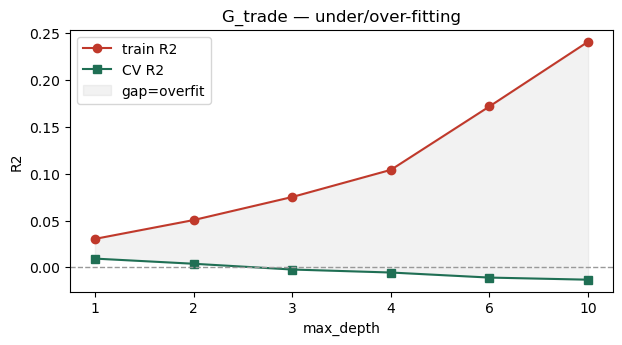

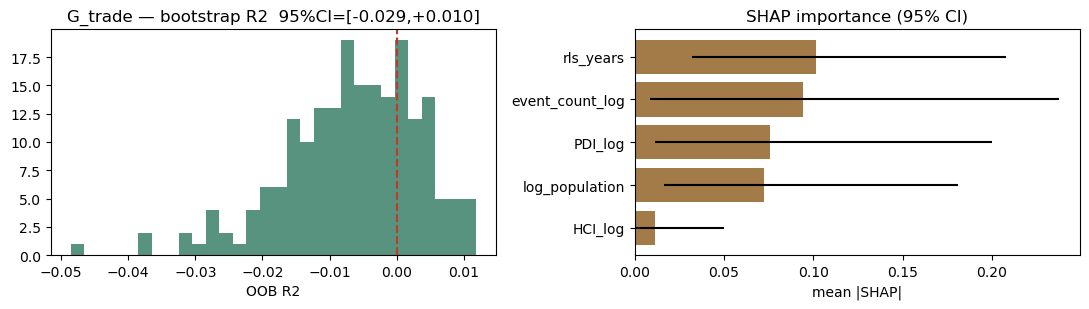


SHAP base value = 4.761 (≈ mean 4.752)
flood share = 52%  |  top = event_count_log


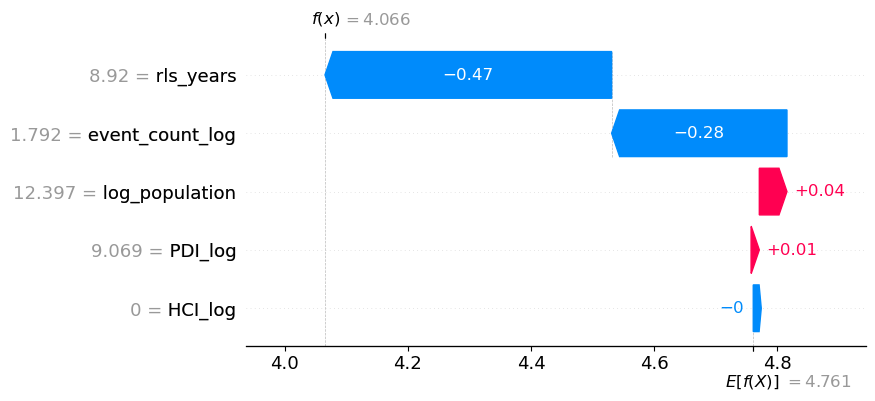

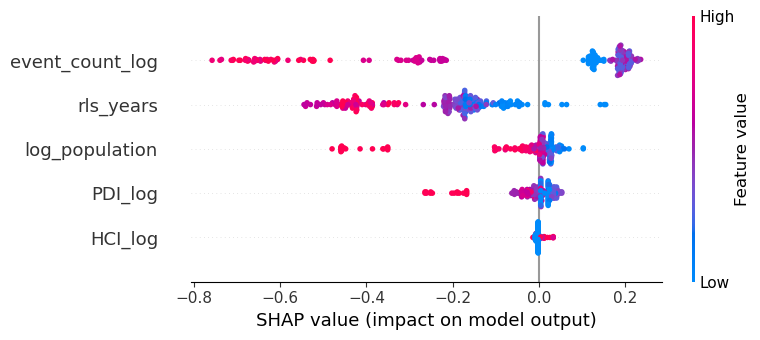

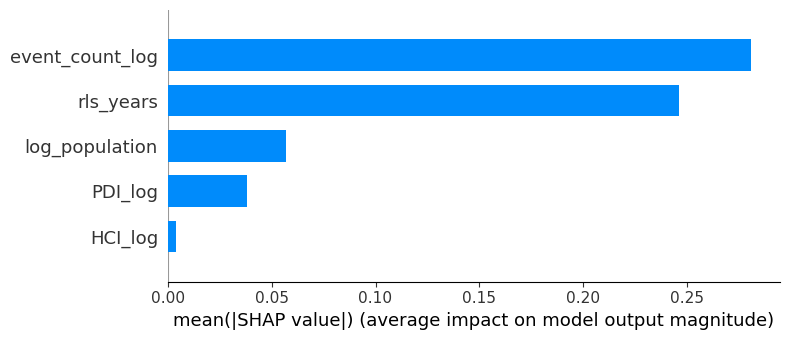

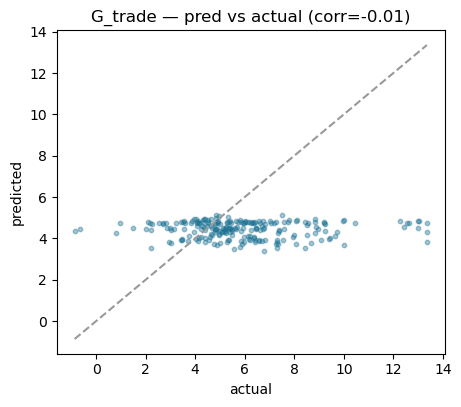

std actual=2.47  std pred=0.39 (16%)

######################################################################
#  SECTOR: H_transport
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 3, 'min_child_weight': 5, 'n_estimators': 100, 'reg_alpha': 0, 'reg_lambda': 1.0, 'subsample': 0.8}
Best grouped-CV R2 (train): +0.0214

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              +0.0227    8.606    5.511
  Validation (2023)       -0.8004    5.554    4.164
  Test (2024-25)          -0.5483    5.043    3.690
  Naive baseline          -0.3910    4.780    3.395


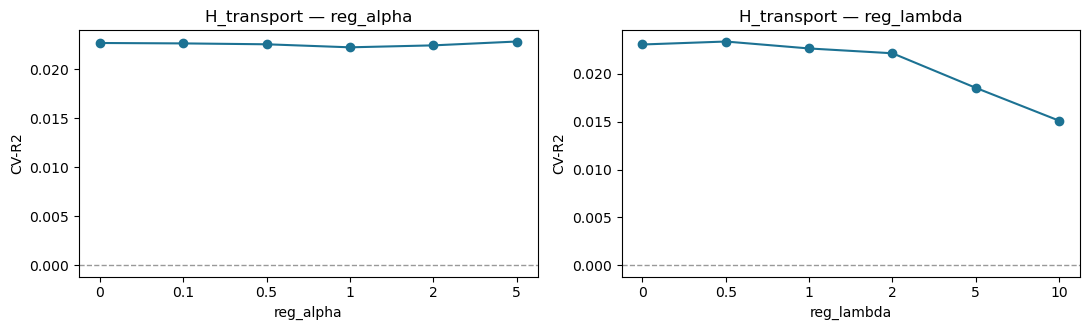

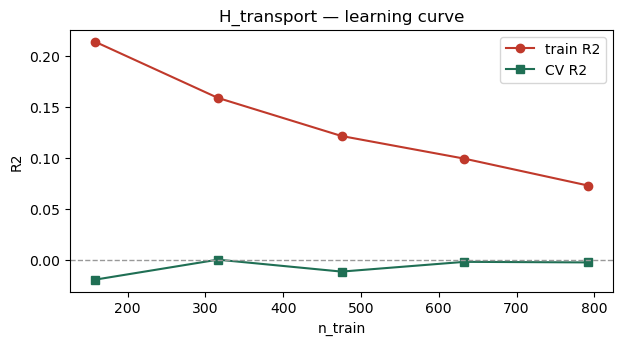

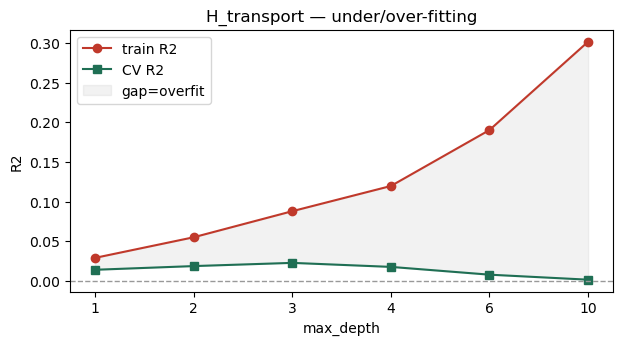

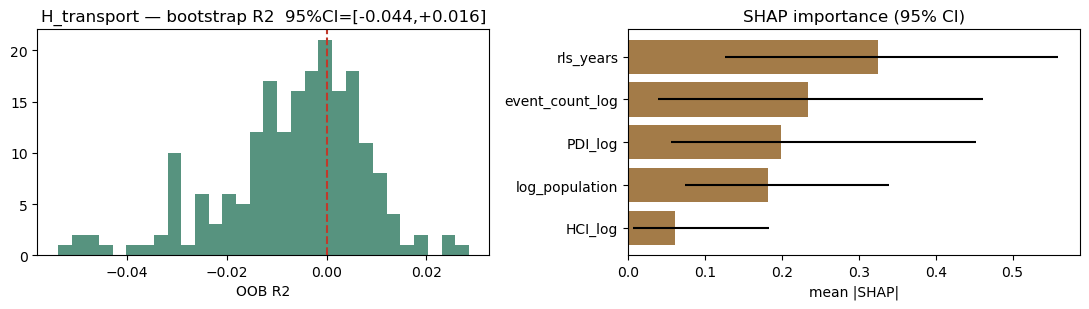


SHAP base value = 4.066 (≈ mean 4.050)
flood share = 38%  |  top = rls_years


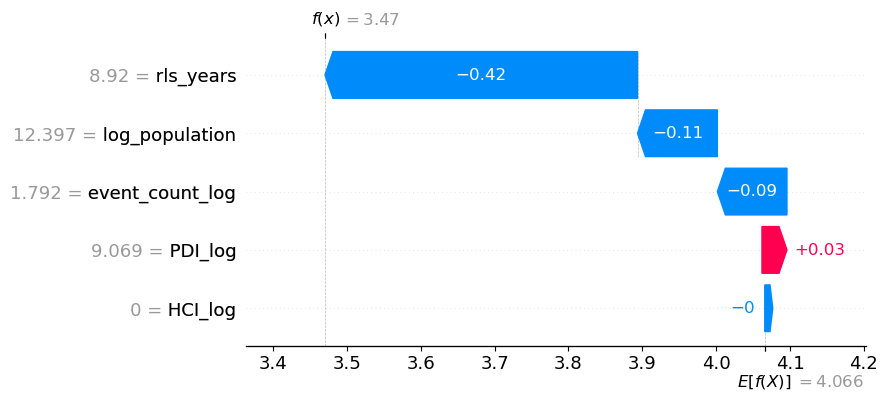

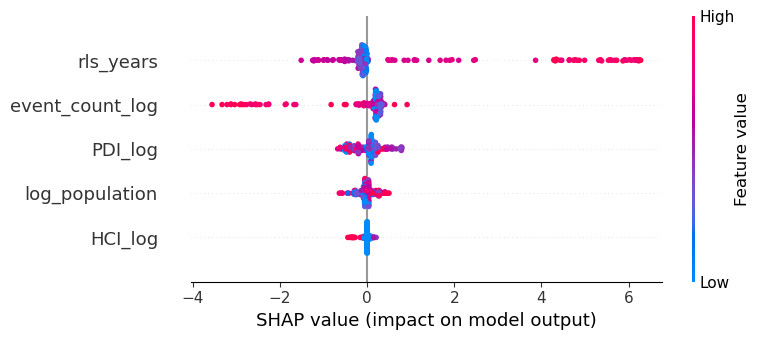

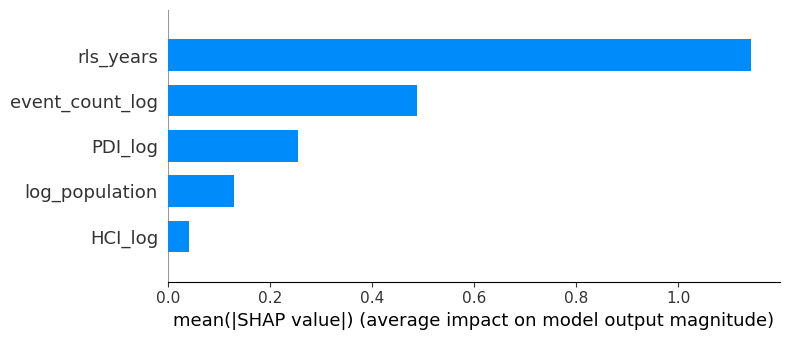

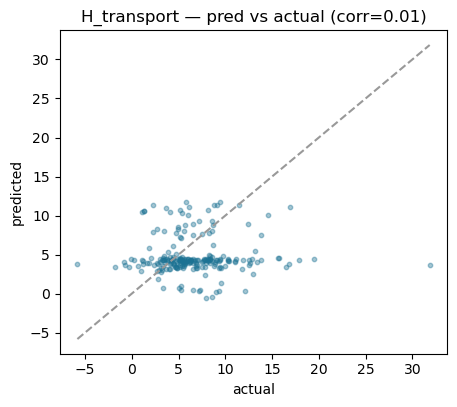

std actual=4.05  std pred=2.44 (60%)

######################################################################
#  SECTOR: I_accommodation
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 4, 'min_child_weight': 10, 'n_estimators': 100, 'reg_alpha': 1.0, 'reg_lambda': 5.0, 'subsample': 0.8}
Best grouped-CV R2 (train): -0.0059

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              -0.0072    6.957    4.974
  Validation (2023)       -1.0513    5.246    4.275
  Test (2024-25)          -0.5226    4.913    3.681
  Naive baseline          -0.4245    4.752    3.562


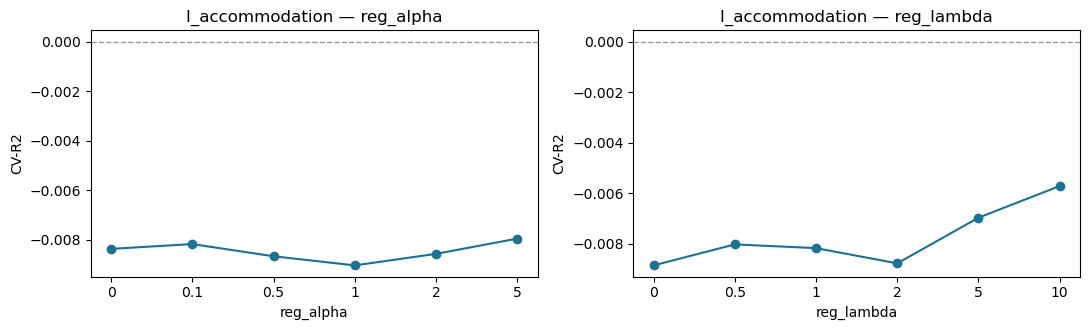

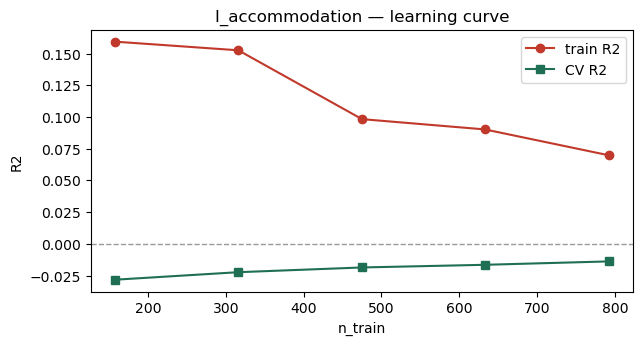

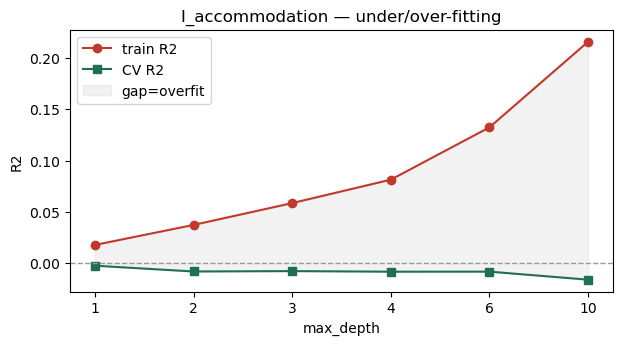

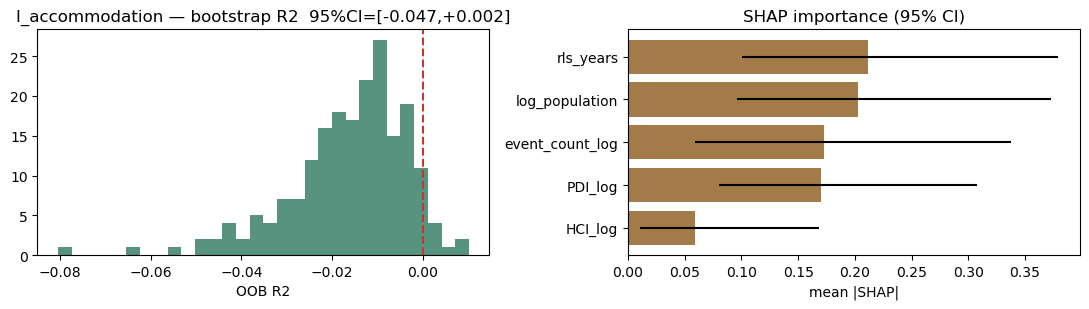


SHAP base value = 5.134 (≈ mean 5.117)
flood share = 48%  |  top = event_count_log


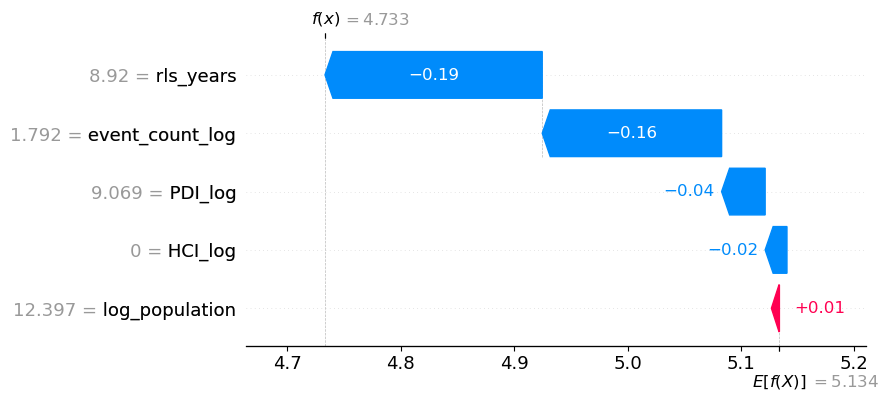

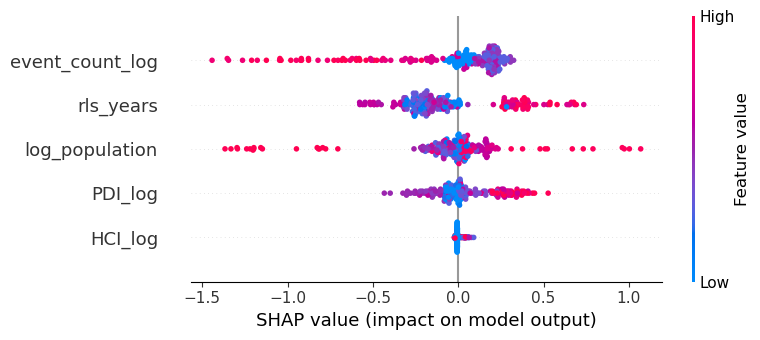

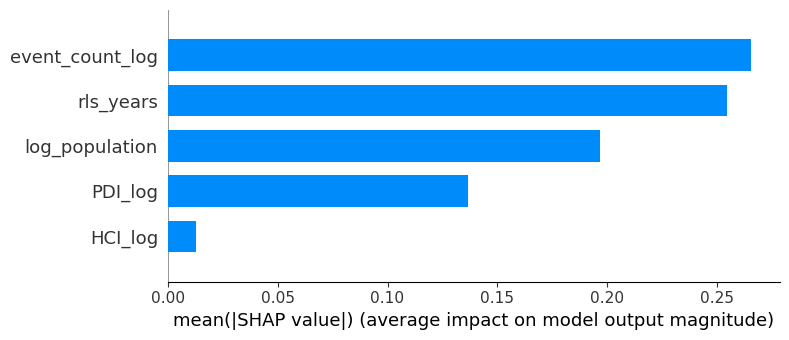

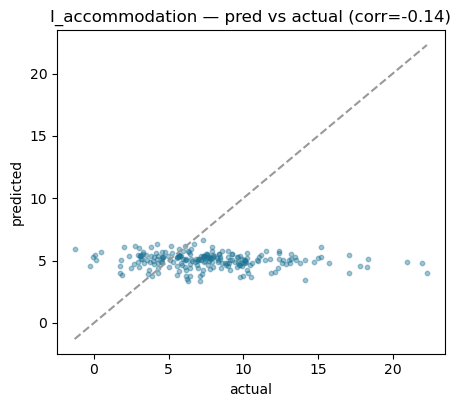

std actual=3.98  std pred=0.60 (15%)

######################################################################
#  SECTOR: J_infocomm
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 10, 'n_estimators': 100, 'reg_alpha': 1.0, 'reg_lambda': 5.0, 'subsample': 0.8}
Best grouped-CV R2 (train): -0.0265

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              -0.0270    3.039    2.275
  Validation (2023)       -0.0828    2.779    2.012
  Test (2024-25)          -0.2994    2.906    2.356
  Naive baseline          -0.4689    3.090    2.553


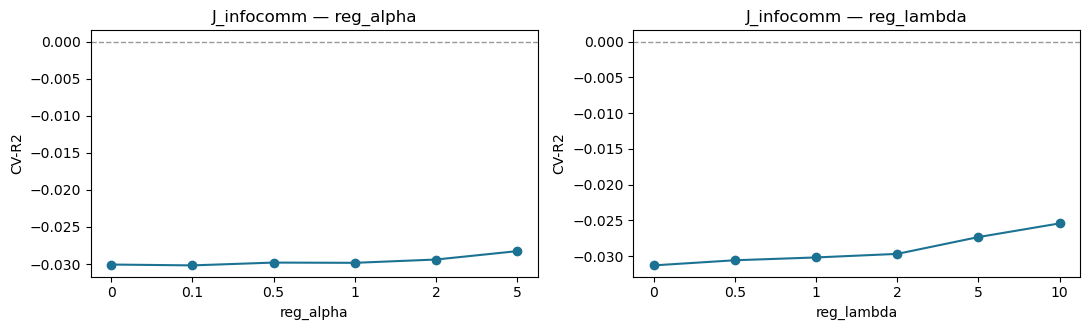

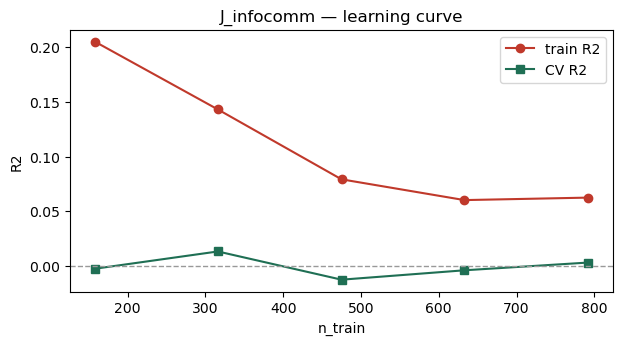

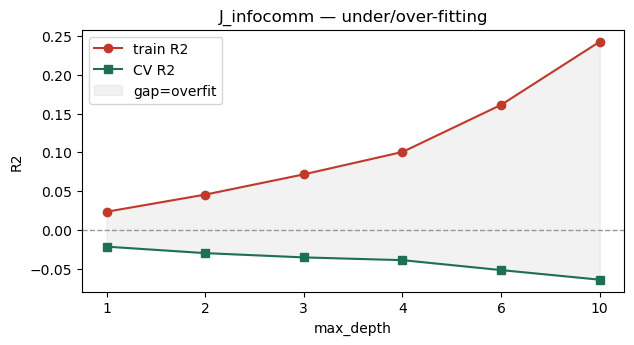

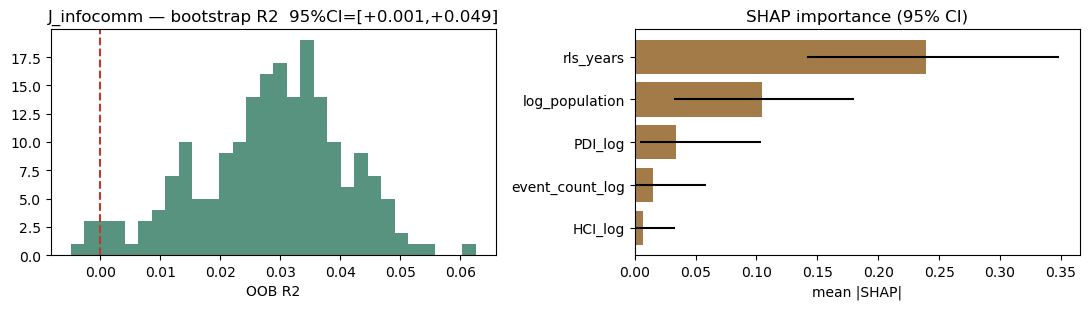


SHAP base value = 7.377 (≈ mean 7.379)
flood share = 21%  |  top = rls_years


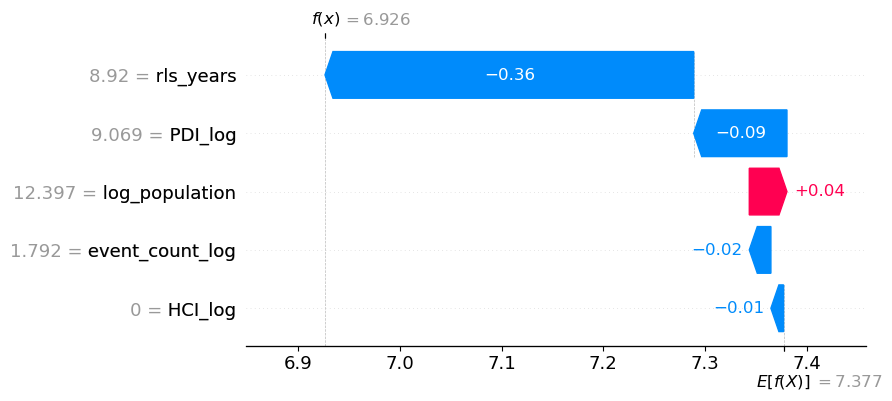

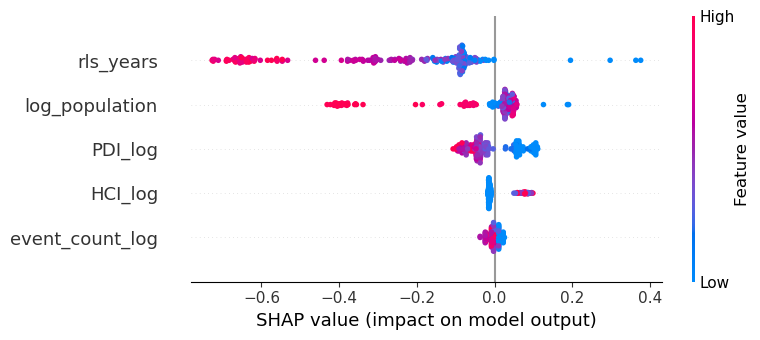

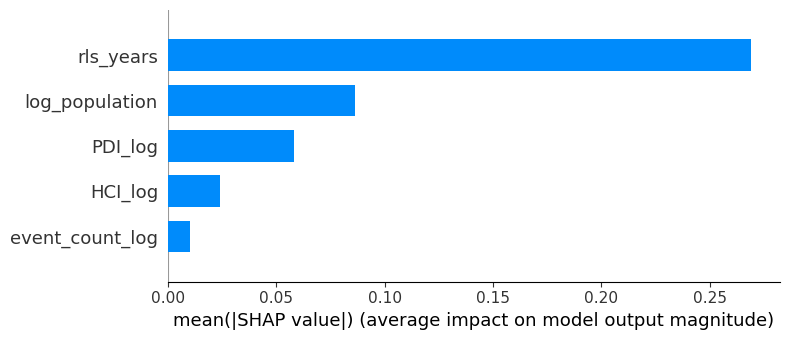

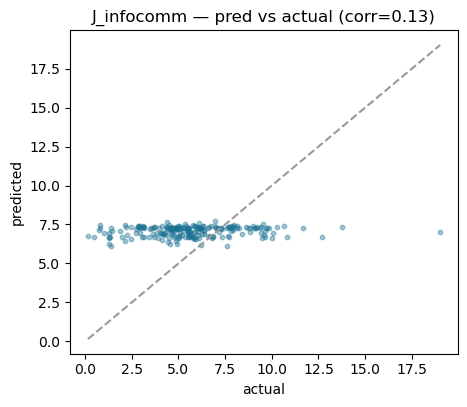

std actual=2.55  std pred=0.32 (12%)

######################################################################
#  SECTOR: K_finance
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 10, 'n_estimators': 100, 'reg_alpha': 0.1, 'reg_lambda': 5.0, 'subsample': 0.8}
Best grouped-CV R2 (train): -0.0062

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              -0.0070    3.403    2.634
  Validation (2023)       -0.0015    4.876    3.712
  Test (2024-25)          -0.3429    4.397    3.130
  Naive baseline          -0.2851    4.302    3.069


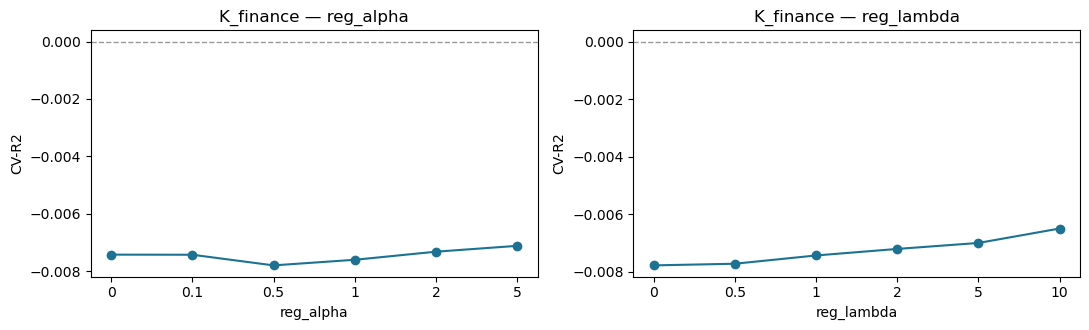

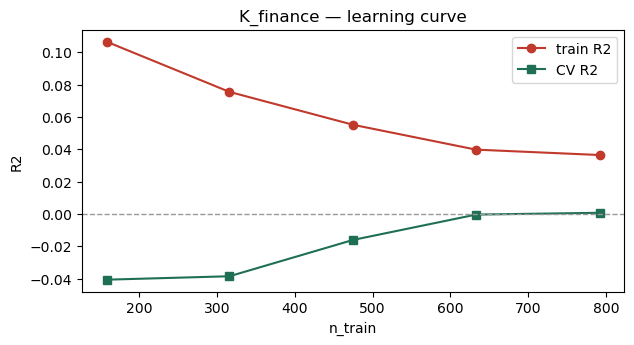

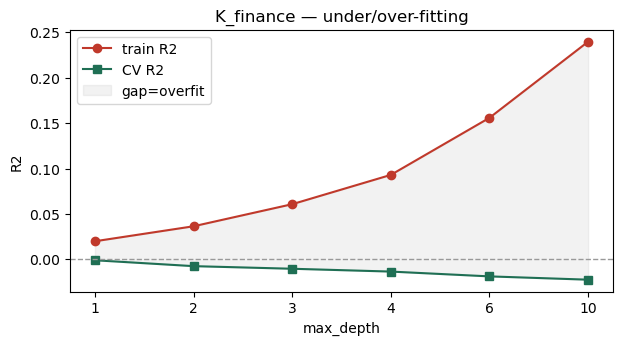

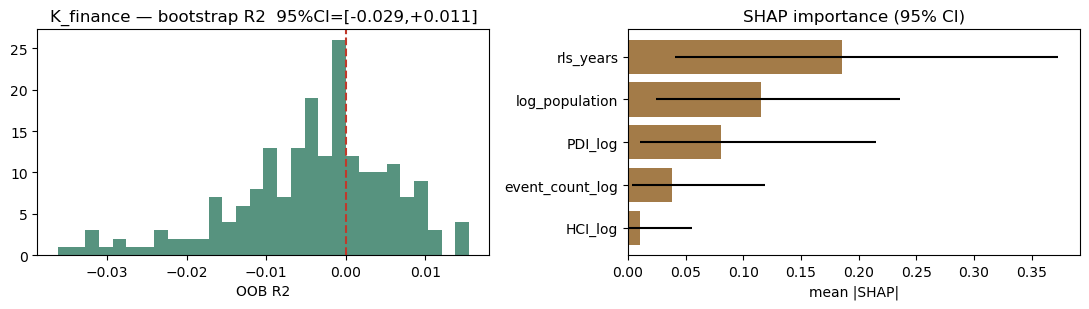


SHAP base value = 3.440 (≈ mean 3.436)
flood share = 11%  |  top = rls_years


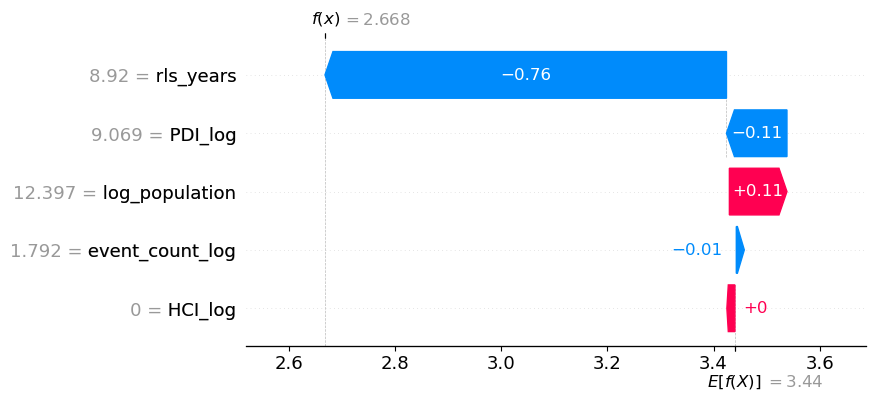

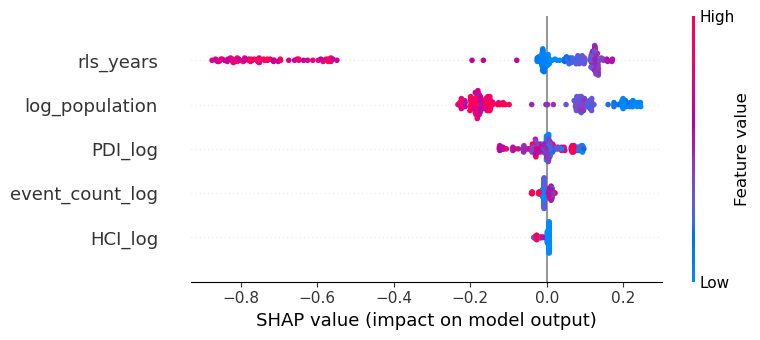

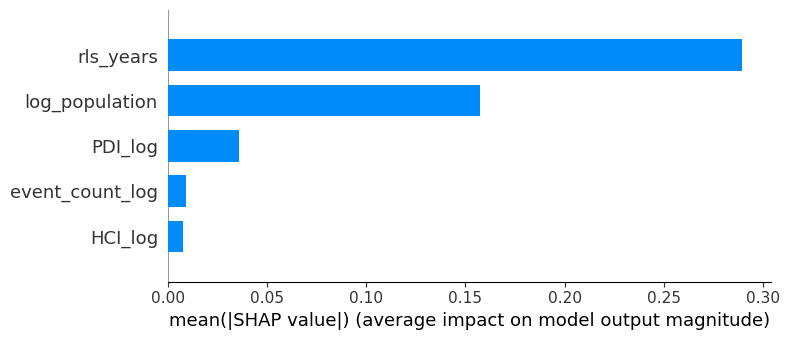

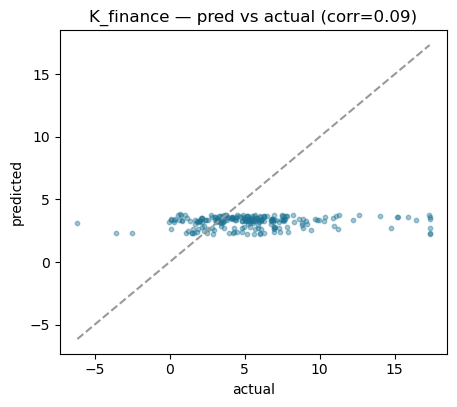

std actual=3.79  std pred=0.44 (12%)

######################################################################
#  SECTOR: L_realestate
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 500, 'reg_alpha': 0.1, 'reg_lambda': 1.0, 'subsample': 0.8}
Best grouped-CV R2 (train): +0.0193

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              +0.0192    2.504    2.024
  Validation (2023)       -0.2629    2.384    1.891
  Test (2024-25)          -0.8350    2.787    2.207
  Naive baseline          -0.3879    2.424    1.846


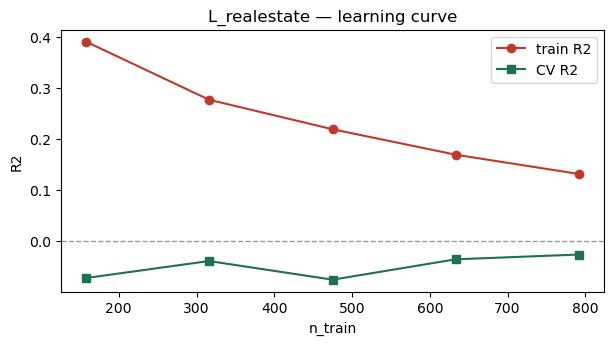

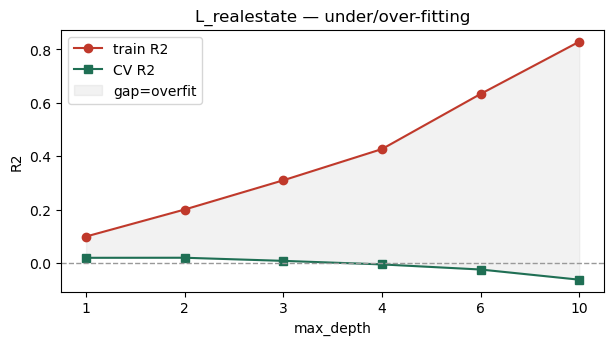

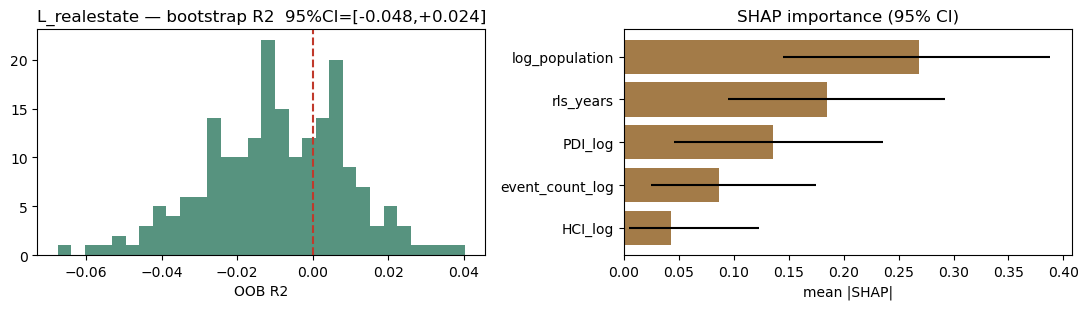


SHAP base value = 3.858 (≈ mean 3.850)
flood share = 37%  |  top = rls_years


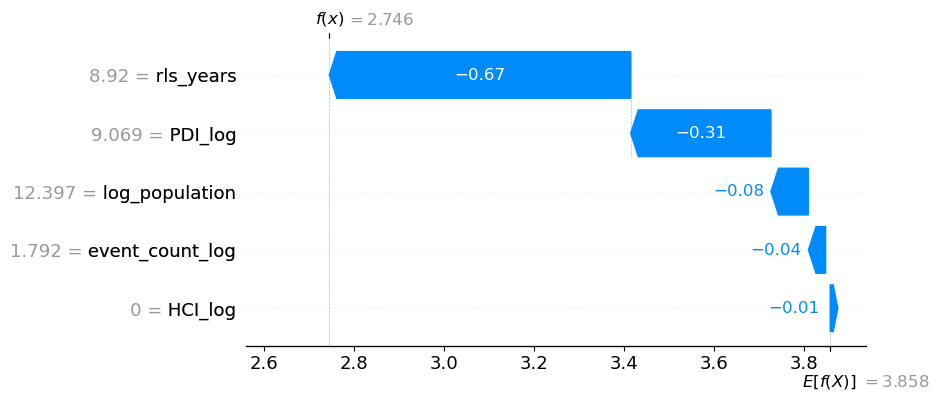

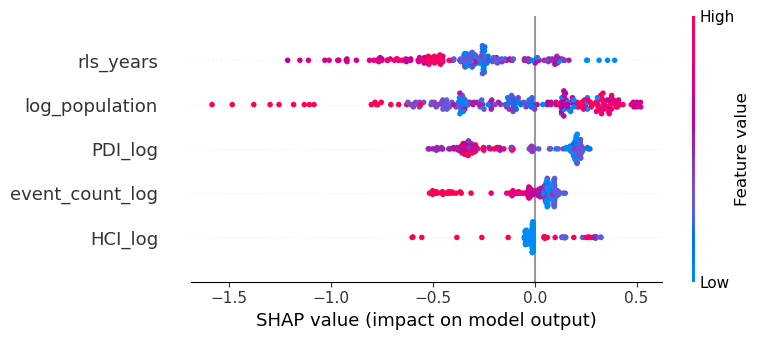

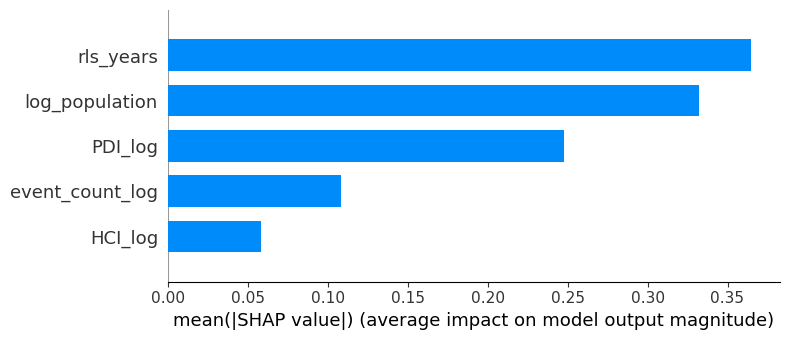

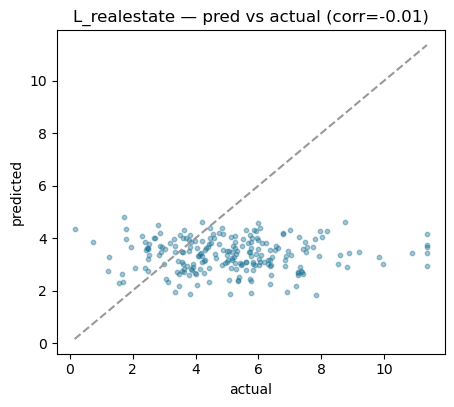

std actual=2.06  std pred=0.62 (30%)

######################################################################
#  SECTOR: MN_business
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 300, 'reg_alpha': 1.0, 'reg_lambda': 1.0, 'subsample': 0.8}
Best grouped-CV R2 (train): +0.0107

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              +0.0101    5.378    3.815
  Validation (2023)       -0.9782    5.162    4.171
  Test (2024-25)          -0.6959    4.137    3.360
  Naive baseline          -0.5153    3.911    3.146


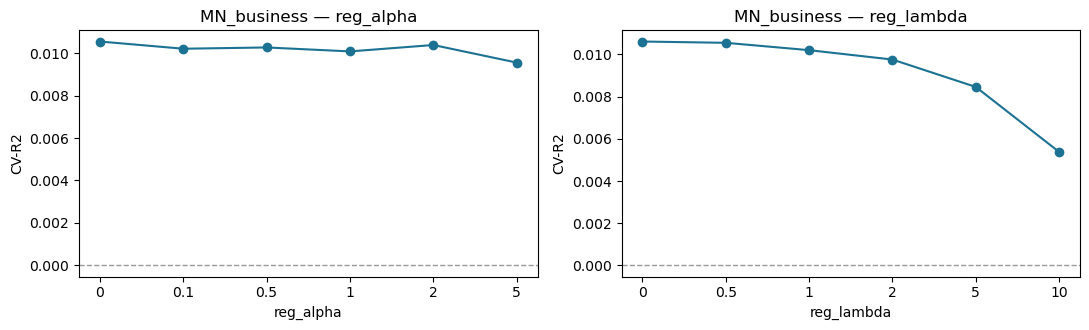

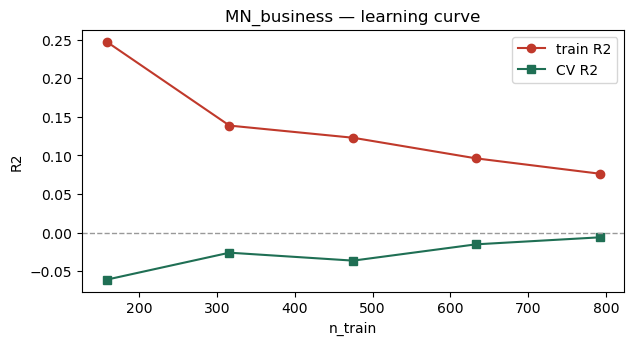

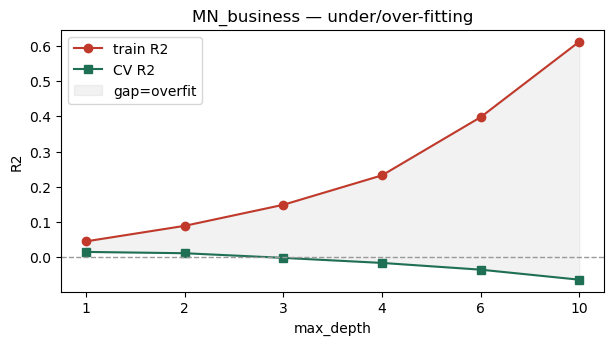

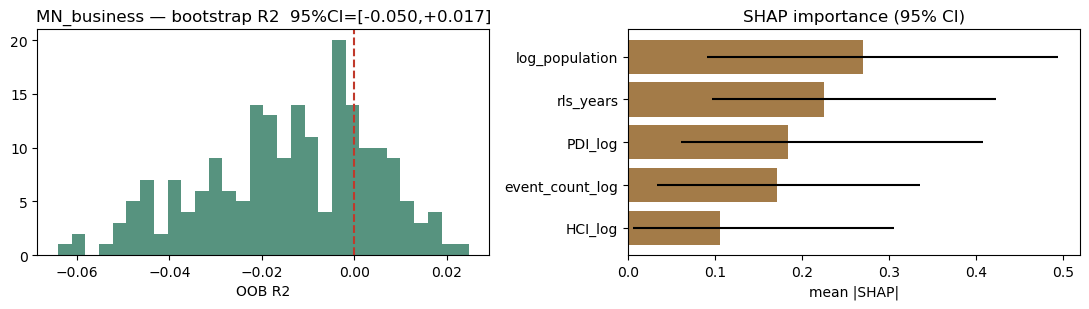


SHAP base value = 3.492 (≈ mean 3.483)
flood share = 66%  |  top = event_count_log


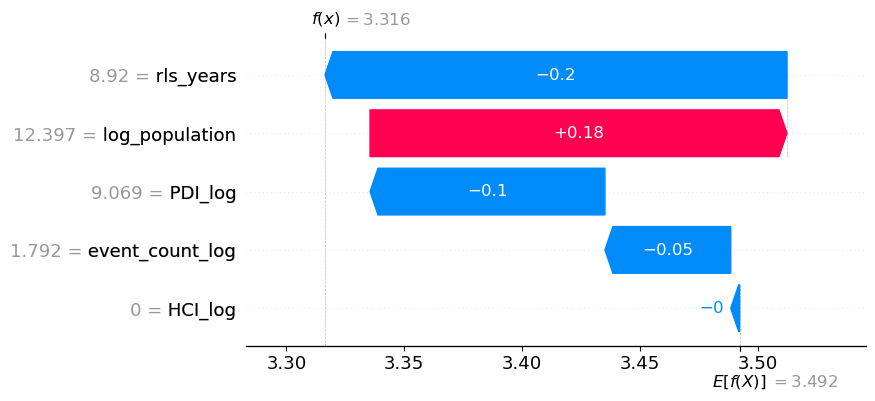

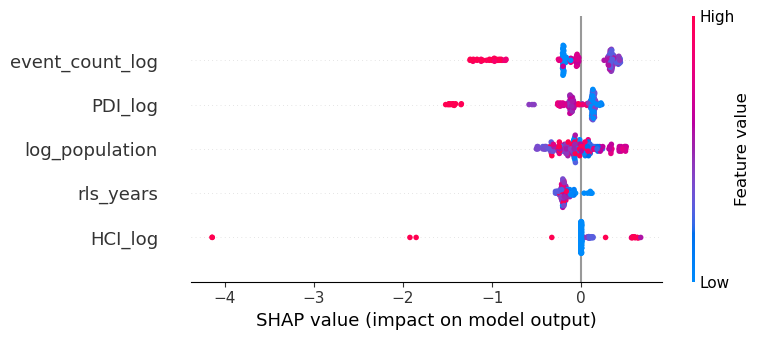

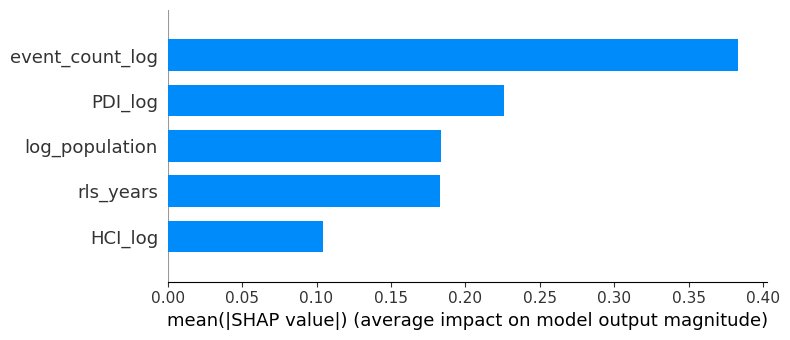

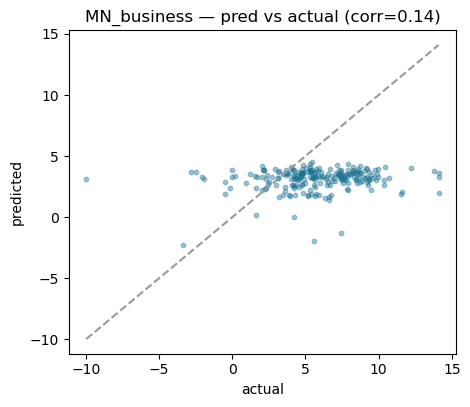

std actual=3.18  std pred=0.92 (29%)

######################################################################
#  SECTOR: O_government
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 3, 'min_child_weight': 5, 'n_estimators': 300, 'reg_alpha': 0.1, 'reg_lambda': 5.0, 'subsample': 0.8}
Best grouped-CV R2 (train): +0.0436

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              +0.0418    3.490    2.792
  Validation (2023)       -0.0908    3.109    2.249
  Test (2024-25)          -0.4986    5.112    4.071
  Naive baseline          -0.2190    4.611    3.716


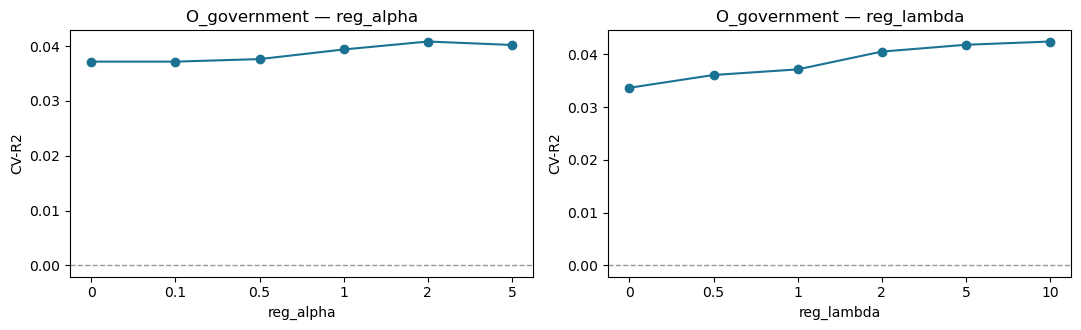

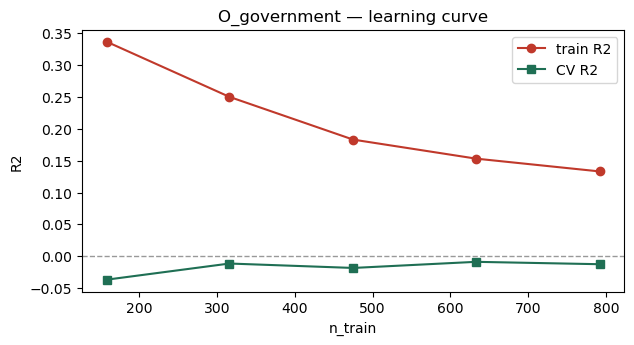

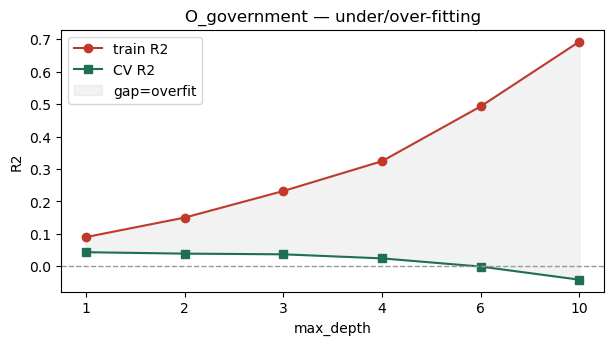

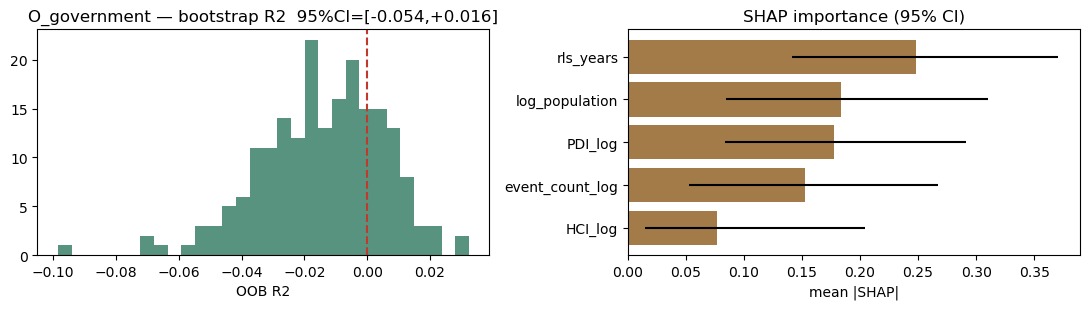


SHAP base value = 2.933 (≈ mean 2.933)
flood share = 30%  |  top = rls_years


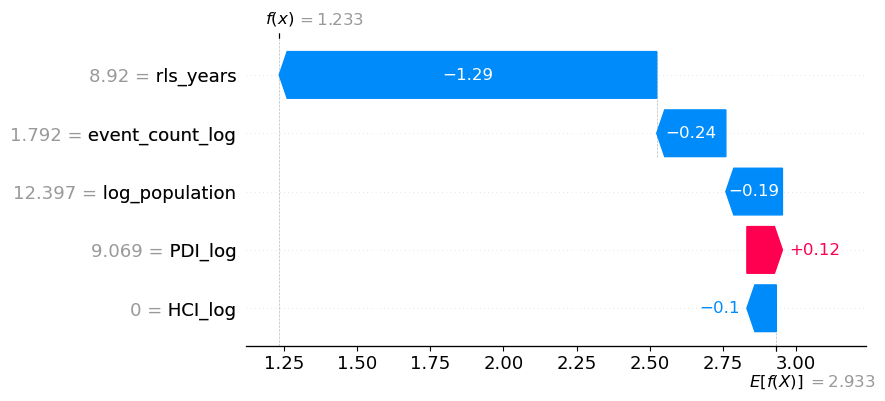

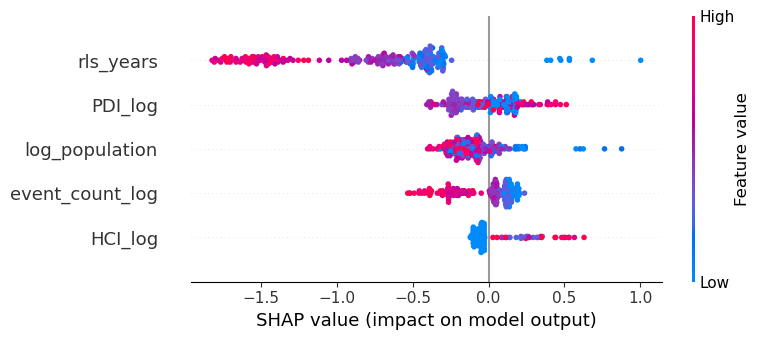

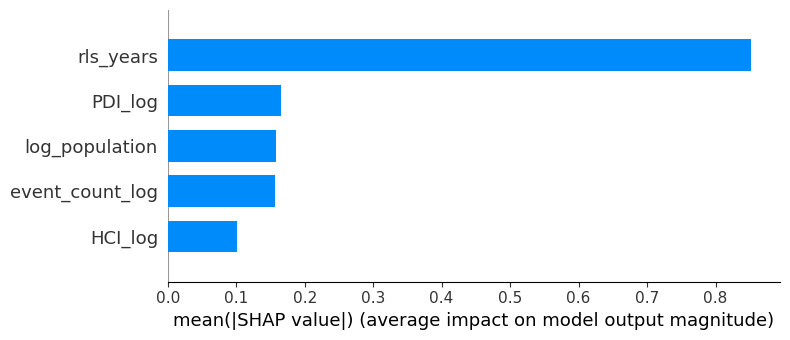

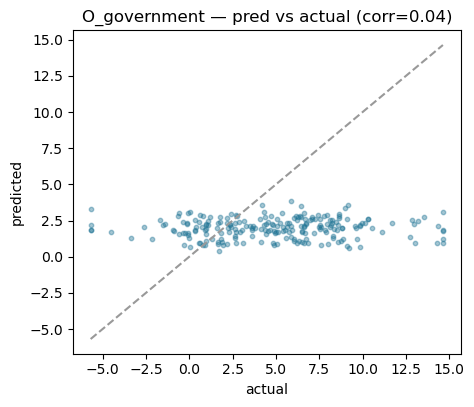

std actual=4.18  std pred=0.68 (16%)

######################################################################
#  SECTOR: P_education
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 4, 'min_child_weight': 10, 'n_estimators': 100, 'reg_alpha': 1.0, 'reg_lambda': 5.0, 'subsample': 0.8}
Best grouped-CV R2 (train): +0.0117

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              +0.0107    2.882    2.306
  Validation (2023)       -0.0731    2.388    1.874
  Test (2024-25)          -0.1518    2.755    2.192
  Naive baseline          -0.0341    2.611    2.085


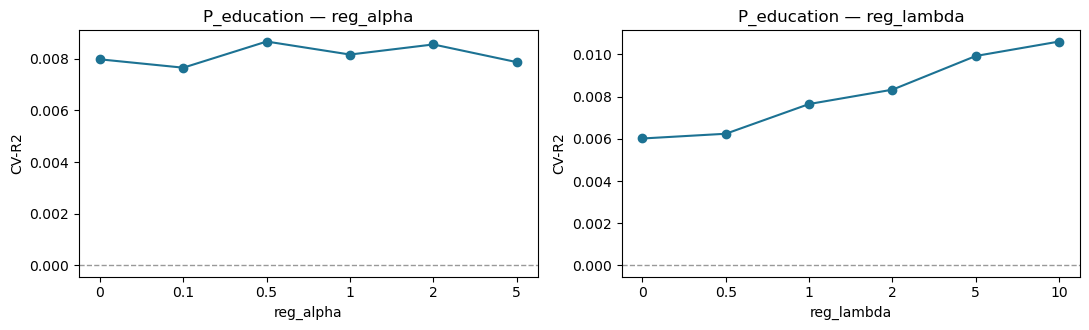

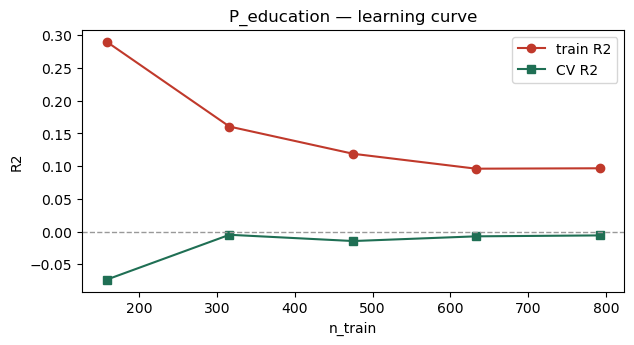

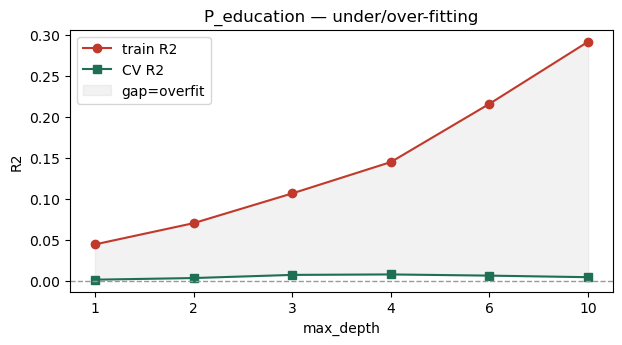

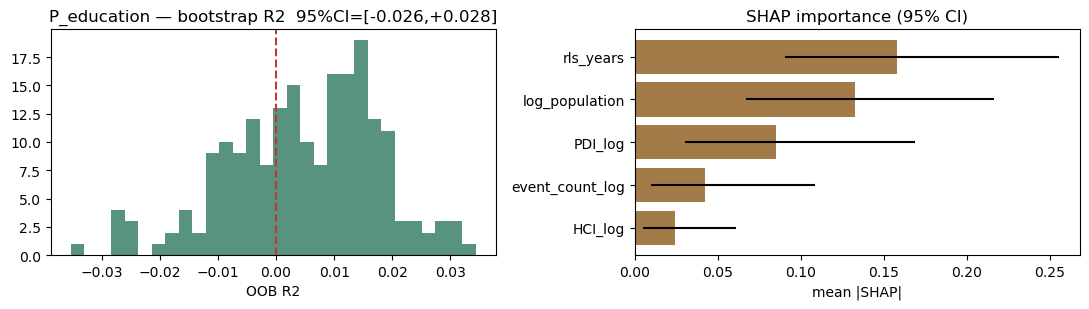


SHAP base value = 4.306 (≈ mean 4.305)
flood share = 22%  |  top = rls_years


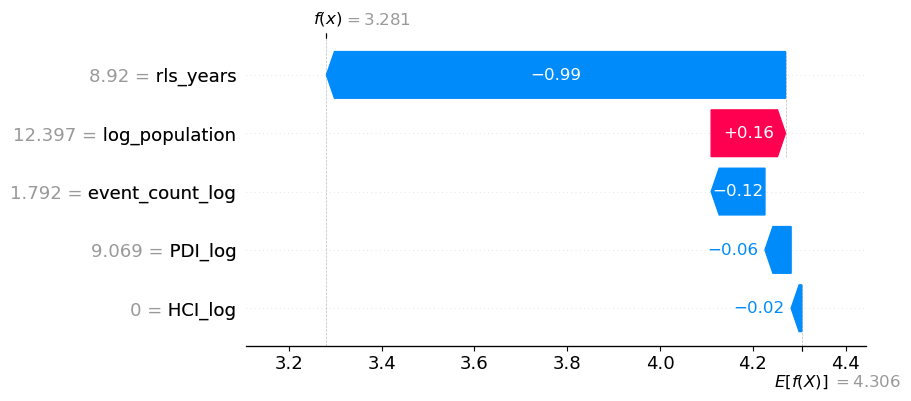

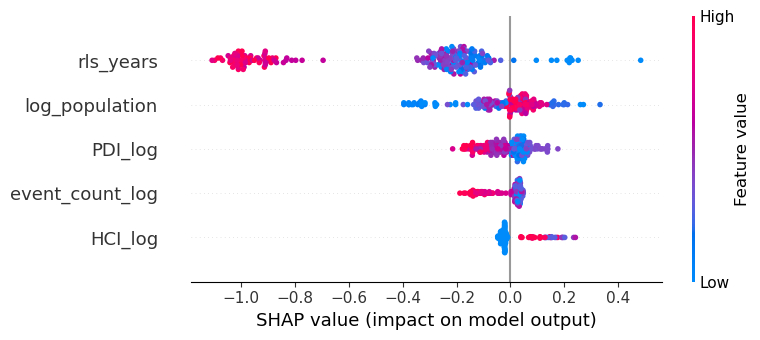

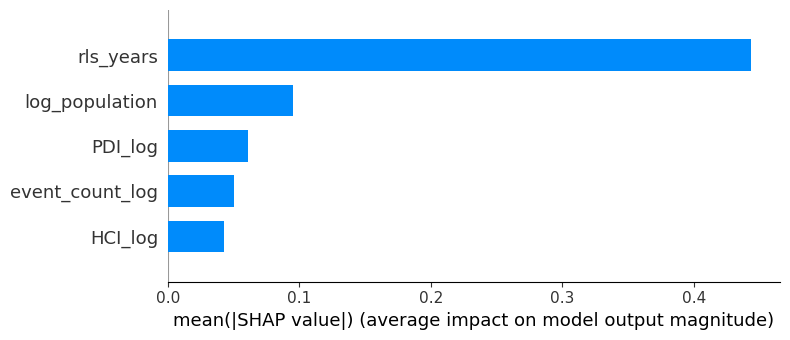

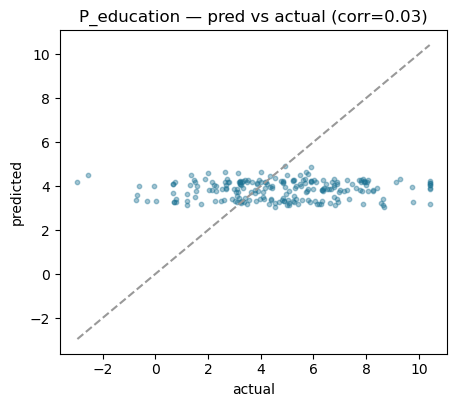

std actual=2.57  std pred=0.42 (16%)

######################################################################
#  SECTOR: Q_health
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 4, 'min_child_weight': 10, 'n_estimators': 100, 'reg_alpha': 0, 'reg_lambda': 1.0, 'subsample': 0.8}
Best grouped-CV R2 (train): -0.0004

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              -0.0008    3.401    2.492
  Validation (2023)       -0.0661    3.635    2.714
  Test (2024-25)          +0.0317    3.189    2.401
  Naive baseline          -0.0128    3.261    2.448


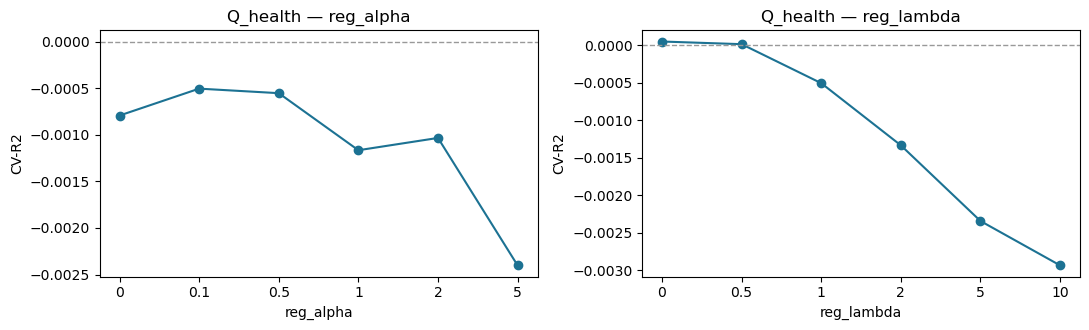

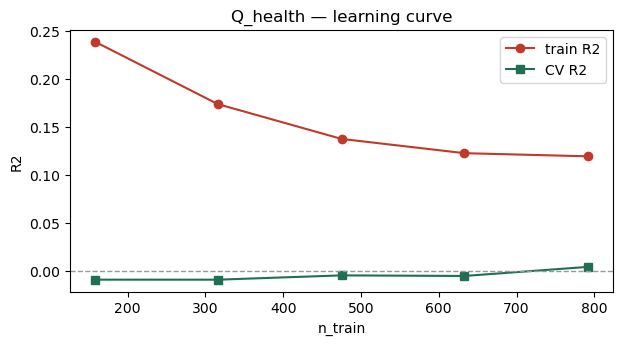

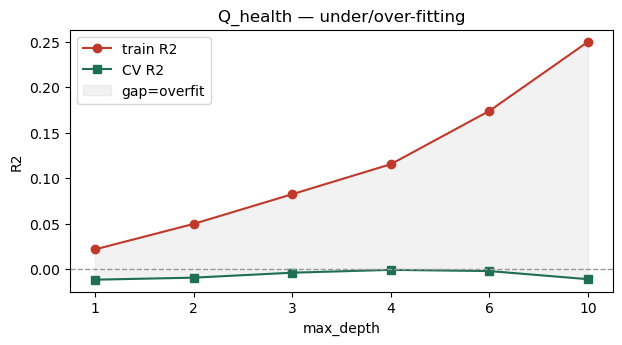

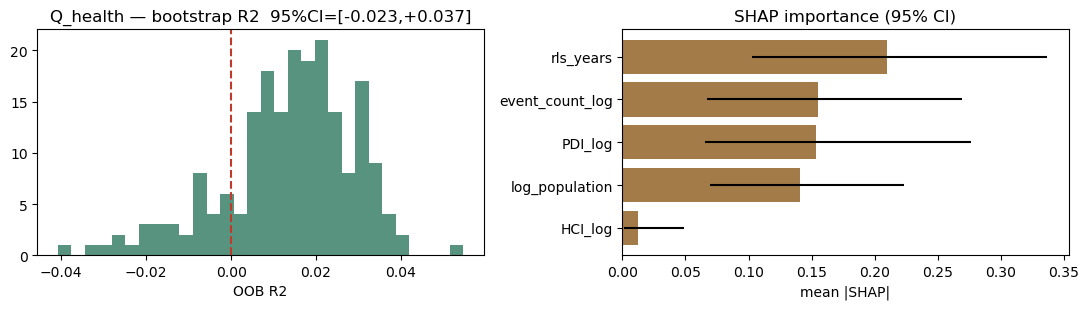


SHAP base value = 6.310 (≈ mean 6.307)
flood share = 37%  |  top = rls_years


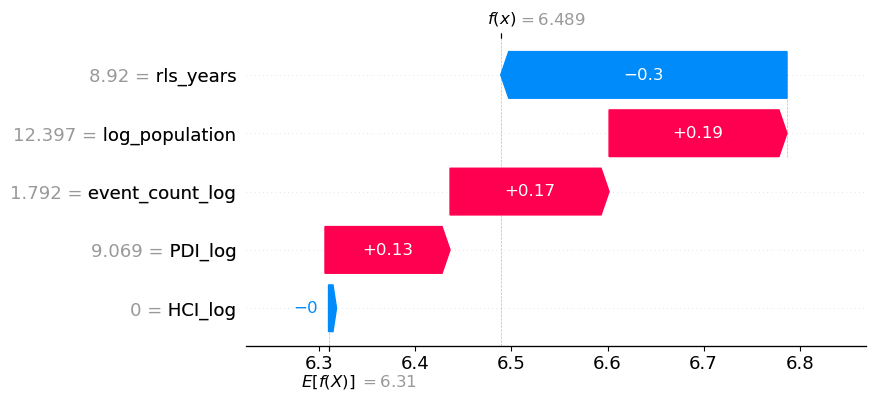

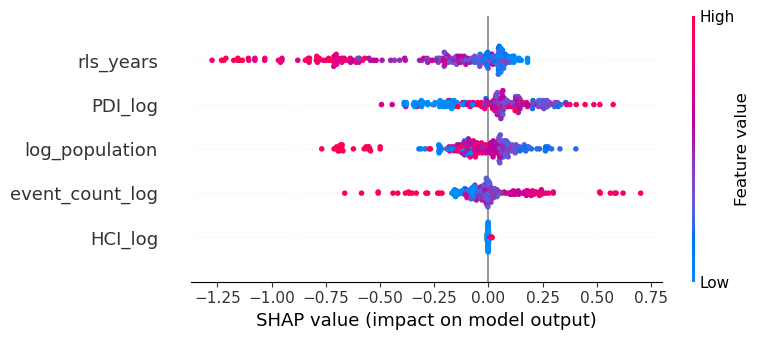

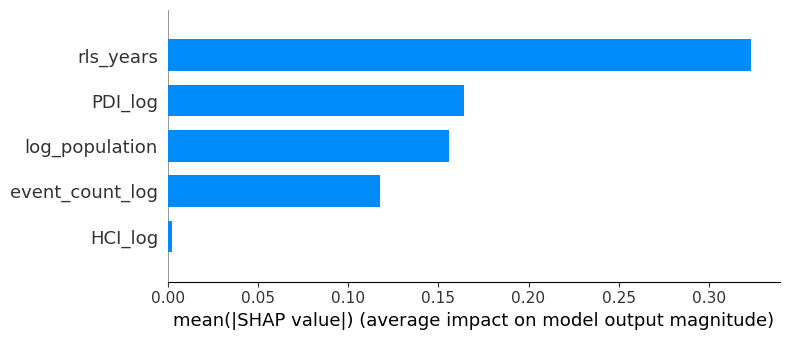

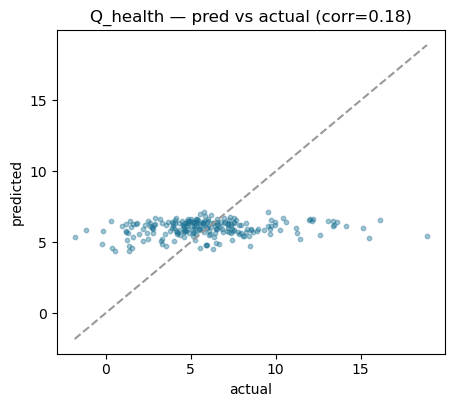

std actual=3.24  std pred=0.54 (17%)

######################################################################
#  SECTOR: RSTU_other
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 3, 'min_child_weight': 5, 'n_estimators': 100, 'reg_alpha': 0, 'reg_lambda': 5.0, 'subsample': 0.8}
Best grouped-CV R2 (train): +0.0132

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              +0.0120    5.756    4.216
  Validation (2023)       -0.7083    4.887    3.796
  Test (2024-25)          -0.5445    4.372    3.435
  Naive baseline          -0.4753    4.273    3.360


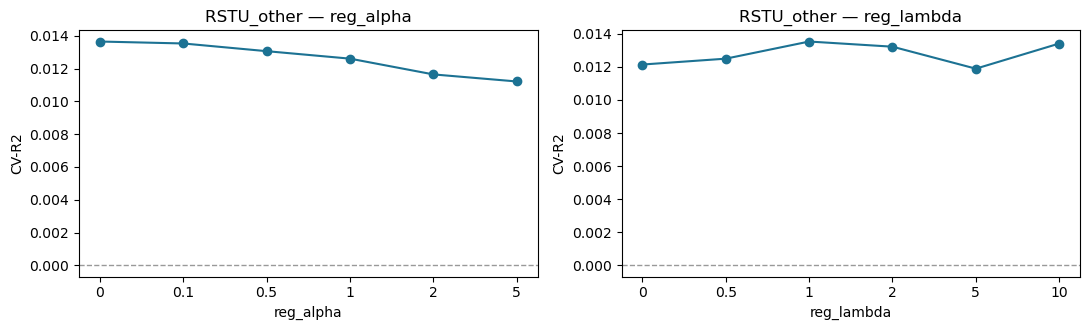

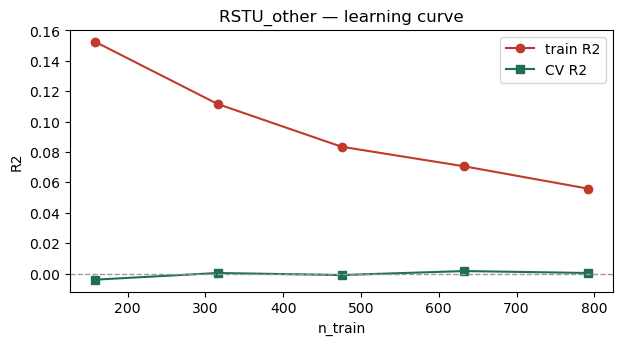

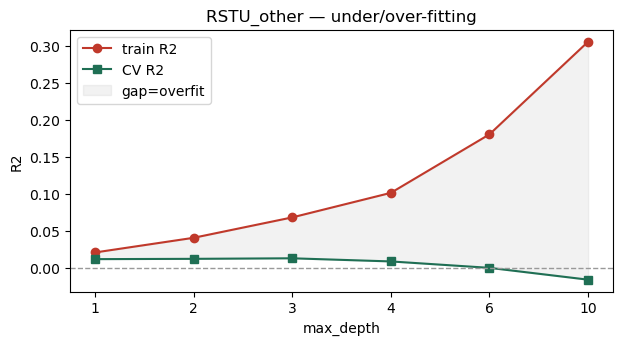

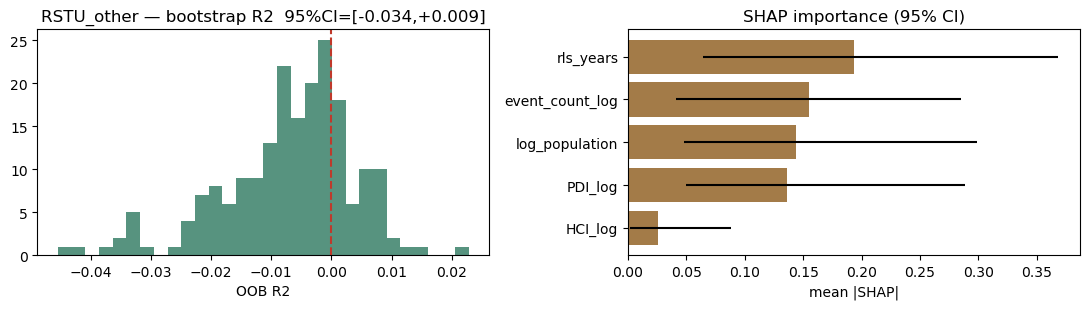


SHAP base value = 4.544 (≈ mean 4.538)
flood share = 64%  |  top = event_count_log


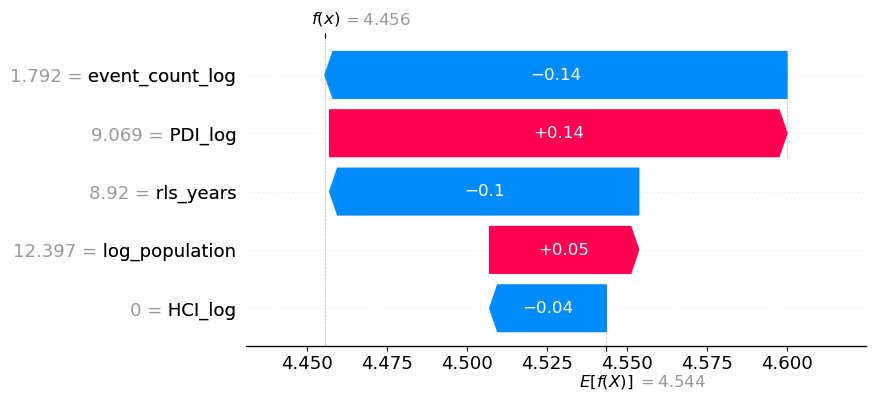

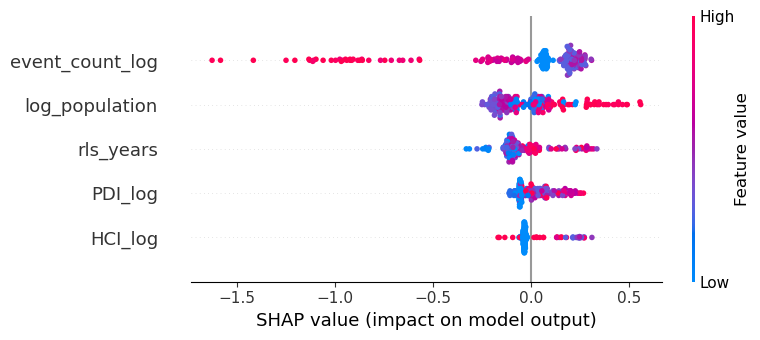

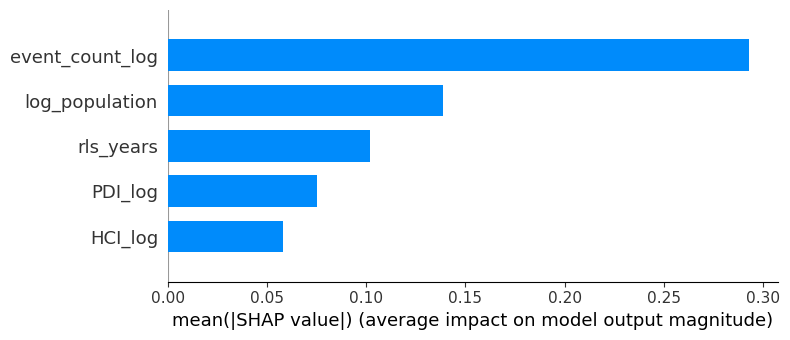

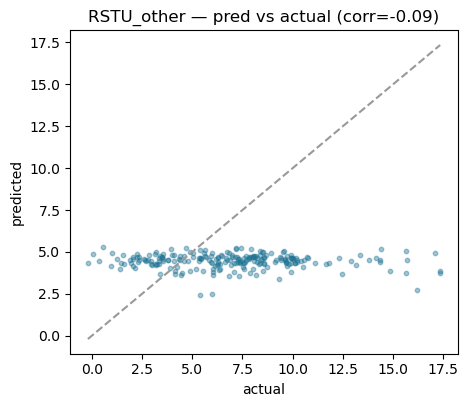

std actual=3.52  std pred=0.43 (12%)

Done.


,sector,best_cv_r2,cv_r2,test_r2,flood_share,top_feature,boot_ci_low,boot_ci_high
0,A_agriculture,-0.013727,-0.013244,-0.171909,67.540002,event_count_log,-0.021575,0.017863
1,B_mining,0.014030,0.014510,-0.015924,34.412470,rls_years,-0.025216,0.039065
2,C_manufacturing,0.003258,0.002928,-0.231944,50.956571,rls_years,-0.025841,0.014032
3,D_electricity,-0.005300,-0.006795,-0.005986,50.592154,rls_years,-0.029081,0.012677
4,E_water,-0.011143,-0.011101,-0.100462,22.521955,rls_years,0.009439,0.053964
5,F_construction,0.008308,0.007725,-0.037192,42.048490,rls_years,-0.019507,0.021238
6,G_trade,0.003994,0.003848,-0.384739,51.589829,event_count_log,-0.028912,0.009575
7,H_transport,0.021361,0.022685,-0.548319,38.214973,rls_years,-0.043565,0.016277
8,I_accommodation,-0.005870,-0.007161,-0.522623,47.886366,event_count_log,-0.046601,0.001564
9,J_infocomm,-0.026454,-0.027010,-0.299359,20.682478,rls_years,0.000824,0.049059


In [8]:
# ═════════════════════════════════════════════════════════════
# STEP 3 — Run the pipeline (per `SECTORS_TO_RUN`)
# ═════════════════════════════════════════════════════════════
xgb_results = []
for s in SECTORS_TO_RUN:
    xgb_results.append(run_full_sector(s))
xgb_sec_df = pd.DataFrame(xgb_results)
print("\nDone.")
xgb_sec_df

## STEP 4 — FE vs XGBoost comparison (FE read from `fit_9b.json`)

FE results come from nb9b. Make sure `fit_9b.json` is in the working directory.

In [10]:
# ═════════════════════════════════════════════════════════════
# STEP 4 — FE vs XGBoost comparison (FE read from `fit_9b.json`)
# ═════════════════════════════════════════════════════════════
# Load FE results exported by nb9b
with open("fit_9b.json") as f:
    fe9b = json.load(f)
fe_lookup = {}
for sec, v in fe9b["sectors"].items():
    sig = []
    for dim in ["event", "HCI", "PDI"]:
        dd = v["dims"].get(dim, {})
        if dd.get("sig_any"):
            sig.append(f"{dim}({dd['beta']:+.2f})")
    fe_lookup[sec] = dict(
        fe_sig=", ".join(sig) if sig else "none sig",
        block_p=v.get("flood_block_pval", np.nan),
        model_sig=v.get("model_significant", False),
    )
# ── Build a rich comparison table ──
rows = []
for _, r in xgb_sec_df.iterrows():
    fe = fe_lookup.get(r.sector, {})
    # flood vs control SHAP share (control = 100 - flood)
    flood = r.get("flood_share", np.nan)
    ctrl  = 100 - flood if pd.notna(flood) else np.nan
    # is the small signal (if any) coming from flood or controls?
    top_is_flood = str(r.get("top_feature", "")) in ["event_count_log", "HCI_log", "PDI_log"]
    signal_src = "flood" if top_is_flood else "control"
    # honest verdict combining CV and test
    cv, te = r.cv_r2, r.test_r2
    if cv > 0.02 and te > 0:
        verdict = "weak signal"          # both slightly positive
    elif cv > 0.02 and te <= 0:
        verdict = "CV-only (fails test)" # looked ok in CV, collapses on test
    else:
        verdict = "no signal"
    rows.append(dict(
        sector=r.sector,
        # ---- FE (inference) ----
        FE_sig=fe.get("fe_sig", "?"),
        FE_block_p=round(fe.get("block_p", np.nan), 3),
        # ---- XGBoost (prediction) ----
        XGB_CV_R2=round(cv, 4),
        XGB_test_R2=round(te, 4),
        boot_CI=f"[{r.get('boot_ci_low', np.nan):+.3f},{r.get('boot_ci_high', np.nan):+.3f}]",
        # ---- SHAP decomposition ----
        flood_pct=f"{flood:.0f}%" if pd.notna(flood) else "?",
        ctrl_pct=f"{ctrl:.0f}%" if pd.notna(ctrl) else "?",
        top_feat=r.get("top_feature", "?"),
        signal_from=signal_src,
        # ---- combined verdict ----
        verdict=verdict,
    ))
cmp_df = pd.DataFrame(rows)
# sort: FE-significant first, then by CV-R2
cmp_df["_fe_any"] = cmp_df.FE_sig != "none sig"
cmp_df = cmp_df.sort_values(["_fe_any", "XGB_CV_R2"], ascending=[False, False]).drop(columns="_fe_any").reset_index(drop=True)
pd.set_option("display.max_columns", None, "display.width", 200)
print("FE (nb9b, inference) vs XGBoost (prediction) — full comparison")
print("=" * 120)
print(cmp_df.to_string(index=False))
print("=" * 120)
# ── Automated reading ──
n_fe_sig   = (cmp_df.FE_sig != "none sig").sum()
n_xgb_weak = (cmp_df.verdict == "weak signal").sum()
n_both     = ((cmp_df.FE_sig != "none sig") & (cmp_df.verdict == "weak signal")).sum()
n_flood_src = (cmp_df.signal_from == "flood").sum()
print("\n── Sharp reading ──")
print(f"• FE finds ≥1 significant flood dimension in {n_fe_sig}/17 sectors (inference).")
print(f"• XGBoost shows a weak signal (CV>0.02 AND test>0) in only {n_xgb_weak}/17 sectors.")
print(f"• Sectors BOTH FE-significant AND XGBoost-predictive: {n_both}/17.")
print(f"• Of all sectors, the top SHAP feature is a flood dimension in {n_flood_src}/17;")
print(f"  in the rest the model leans on CONTROLS (population/schooling), so any")
print(f"  small predictive signal is NOT coming from flooding.")
print("• 'CV-only (fails test)' = looked slightly predictive in cross-validation but")
print("  R² turns negative on the untouched 2024–25 years → not a real signal.")
print("• Bottom line: no sector shows flood-driven predictive power that survives the")
print("  test set; FE-significant sectors (trade, construction…) are the")
print("  significance-≠-prediction pattern, consistent with headline growth.")
cmp_df

FE (nb9b, inference) vs XGBoost (prediction) — full comparison
         sector                   FE_sig  FE_block_p  XGB_CV_R2  XGB_test_R2         boot_CI flood_pct ctrl_pct        top_feat signal_from              verdict
       B_mining               PDI(-0.04)       0.031     0.0145      -0.0159 [-0.025,+0.039]       34%      66%       rls_years     control            no signal
     RSTU_other               HCI(-0.16)       0.044     0.0120      -0.5445 [-0.034,+0.009]       64%      36% event_count_log       flood            no signal
    P_education               HCI(-0.13)       0.001     0.0107      -0.1518 [-0.026,+0.028]       22%      78%       rls_years     control            no signal
    MN_business event(+0.34), HCI(-0.18)       0.001     0.0101      -0.6959 [-0.050,+0.017]       66%      34% event_count_log       flood            no signal
 F_construction event(+0.40), HCI(-0.18)       0.000     0.0077      -0.0372 [-0.020,+0.021]       42%      58%       rls_years     

,sector,FE_sig,FE_block_p,XGB_CV_R2,XGB_test_R2,boot_CI,flood_pct,ctrl_pct,top_feat,signal_from,verdict
0,B_mining,PDI(-0.04),0.031,0.0145,-0.0159,"[-0.025,+0.039]",34%,66%,rls_years,control,no signal
1,RSTU_other,HCI(-0.16),0.044,0.0120,-0.5445,"[-0.034,+0.009]",64%,36%,event_count_log,flood,no signal
2,P_education,HCI(-0.13),0.001,0.0107,-0.1518,"[-0.026,+0.028]",22%,78%,rls_years,control,no signal
3,MN_business,"event(+0.34), HCI(-0.18)",0.001,0.0101,-0.6959,"[-0.050,+0.017]",66%,34%,event_count_log,flood,no signal
4,F_construction,"event(+0.40), HCI(-0.18)",0.000,0.0077,-0.0372,"[-0.020,+0.021]",42%,58%,rls_years,control,no signal
5,G_trade,event(+0.30),0.000,0.0038,-0.3847,"[-0.029,+0.010]",52%,48%,event_count_log,flood,no signal
6,C_manufacturing,PDI(-0.07),0.000,0.0029,-0.2319,"[-0.026,+0.014]",51%,49%,rls_years,control,no signal
7,Q_health,event(+0.39),0.001,-0.0008,0.0317,"[-0.023,+0.037]",37%,63%,rls_years,control,no signal
8,I_accommodation,HCI(-0.18),0.000,-0.0072,-0.5226,"[-0.047,+0.002]",48%,52%,event_count_log,flood,no signal
9,O_government,none sig,0.283,0.0418,-0.4986,"[-0.054,+0.016]",30%,70%,rls_years,control,CV-only (fails test)
